# EMS Response-Time Research: Temporal Drift, Uncertainty, and Latent States

This notebook studies response-time prediction from incident-start information using NYC EMS incident data. It compares chronological forecasting models, evaluates uncertainty under temporal shift, and explores shared residual dynamics and adjusted observational associations.

**Reproduction:** Inputs are `data/incident_history.csv` and `data/incidents_to_predict.csv`. `prepare_data.py` documents their acquisition, `data/acquisition_manifest.json` records the downloaded snapshot, and `requirements.txt` lists dependencies. Run the notebook from this directory, top to bottom. The final validation cell reports the current results; all numerical conclusions should refer to those executed outputs.

**Interpretation and limitations:**

- M1 is selected using development-period backtests. Pressure features count all incoming incidents in the preceding 90 minutes, excluding simultaneous and future arrivals. The first 90 minutes of the source history have incomplete lookback coverage. The analysis assumes recorded initial fields were available at incident start; this retrospective extract does not verify field revision timing.
- The joint call-type/severity OLS design is rejected for coefficient interpretation because it is rank-deficient. The retained descriptive OLS model adjusts for severity, weekday, and month, not call type.
- CQR coverage is measured on a later holdout, not assumed to equal the nominal 90%. The holdout is subsequently reused only to calibrate intervals for the still-later unlabeled prediction week. Future accuracy and coverage cannot be measured without outcomes.
- HMM and Kalman corrections use in-sample development residuals and were explored after inspecting the holdout. They assume previous-day response outcomes are available before the next day's predictions; reporting delays are not simulated. Their comparisons need a new prospective test.
- Held-incident residualization is a chronological sample-split **adjusted observational association**, not a demonstrated causal effect. The separate held-residual bootstrap is conditional on its fitted reference model.

These analyses are exploratory research, not validated deployment claims.

## Results from the clean-kernel run

| Evaluation | Result |
|---|---:|
| M1 pooled development OOF MAE | 587.58 seconds |
| M1 plus incoming-call pressure OOF MAE | 590.45 seconds |
| M0 holdout MAE | 553.84 seconds |
| M1 holdout MAE | 541.42 seconds |
| M1 + HMM exploratory holdout MAE | 537.80 seconds |
| M1 + Kalman exploratory holdout MAE | 541.63 seconds |
| Nominal 90% CQR holdout coverage | 84.45% |
| Future incident predictions | 30,197 |
| Future incidents flagged for review | 4,087 (13.53%) |

M1 remains the lowest-error model in the pooled development comparison. Adding incoming-call pressure does not improve its pooled MAE in this experiment. The small HMM improvement remains exploratory. CQR intervals under-cover the later holdout, so nominal 90% coverage should not be promised operationally. Future flags use a strict threshold above the 85th percentile; tied interval widths mean the flagged fraction is below 15%.

The sample-split held-incident residualization estimate is **1,480.29 seconds** and is interpreted as an adjusted association. It differs from the separate held-only adjusted residual mean because the two procedures estimate different quantities.


## Data loading

Load the acquired CSVs from `data/`. Historical outcomes support retrospective evaluation; the future input file contains incident-start fields without response outcomes. The acquisition manifest identifies the source snapshot.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

# Bounded previews make repeated notebook runs safe in an existing session.
pd.reset_option("display")
pd.set_option("display.max_rows", 100)
DATA_DIR = Path("data")

history = pd.read_csv(DATA_DIR / "incident_history.csv", low_memory=False)
future = pd.read_csv(DATA_DIR / "incidents_to_predict.csv", low_memory=False)

print("history:", history.shape)
print("future:", future.shape)


history: (913796, 31)
future: (30197, 12)


In [2]:
history.head()

,incident_id,incident_datetime,initial_call_type,initial_severity_level_code,final_call_type,final_severity_level_code,first_assignment_datetime,valid_dispatch_rspns_time_indc,dispatch_response_seconds_qy,first_activation_datetime,...,citycouncildistrict,communitydistrict,communityschooldistrict,congressionaldistrict,reopen_indicator,special_event_indicator,standby_indicator,transfer_indicator,first_to_hosp_datetime,first_hosp_arrival_datetime
0,79512445,2024-05-01T00:00:02.000,DRUG,4,DRUG,4,2024-05-01T00:00:46.000,Y,44,2024-05-01T00:01:06.000,...,40.0,314.0,22.0,9.0,N,N,N,N,NaN,NaN
1,79512446,2024-05-01T00:00:40.000,STNDBM,8,STNDBM,8,2024-05-01T04:54:29.000,Y,17629,2024-05-01T04:55:09.000,...,41.0,316.0,23.0,9.0,Y,N,N,N,NaN,NaN
2,79512447,2024-05-01T00:00:44.000,STNDBM,8,STNDBM,8,2024-05-01T04:46:03.000,Y,17119,2024-05-01T04:46:38.000,...,37.0,304.0,32.0,7.0,Y,N,N,N,NaN,NaN
3,79512448,2024-05-01T00:00:48.000,STNDBY,8,STNDBY,8,2024-05-01T06:24:45.000,Y,23037,2024-05-01T06:24:45.000,...,8.0,111.0,4.0,12.0,Y,N,Y,N,NaN,NaN
4,79512449,2024-05-01T00:00:59.000,UNKNOW,4,DRUG,4,2024-05-01T00:01:14.000,Y,15,2024-05-01T00:01:33.000,...,14.0,208.0,10.0,13.0,N,N,N,N,2024-05-01T00:16:08.000,2024-05-01T00:27:59.000


In [3]:
future.head()

,incident_id,incident_datetime,initial_call_type,initial_severity_level_code,borough,incident_dispatch_area,zipcode,policeprecinct,citycouncildistrict,communitydistrict,communityschooldistrict,congressionaldistrict
0,80690035,2024-11-18T00:00:18.000,UNKNOW,4,QUEENS,Q7,11357.0,109.0,19.0,407.0,25.0,3.0
1,80690037,2024-11-18T00:00:47.000,UNC,2,QUEENS,Q6,11368.0,110.0,21.0,404.0,24.0,14.0
2,80690038,2024-11-18T00:01:04.000,INBLED,4,BRONX,B5,10458.0,52.0,15.0,207.0,10.0,13.0
3,80690040,2024-11-18T00:01:23.000,CARDBR,2,BROOKLYN,K2,11219.0,66.0,44.0,312.0,20.0,10.0
4,80690041,2024-11-18T00:01:26.000,STATEP,2,BROOKLYN,K7,11222.0,94.0,33.0,301.0,14.0,12.0


In [4]:
history.columns.tolist()

['incident_id',
 'incident_datetime',
 'initial_call_type',
 'initial_severity_level_code',
 'final_call_type',
 'final_severity_level_code',
 'first_assignment_datetime',
 'valid_dispatch_rspns_time_indc',
 'dispatch_response_seconds_qy',
 'first_activation_datetime',
 'first_on_scene_datetime',
 'valid_incident_rspns_time_indc',
 'incident_response_seconds_qy',
 'incident_travel_tm_seconds_qy',
 'incident_close_datetime',
 'held_indicator',
 'incident_disposition_code',
 'borough',
 'incident_dispatch_area',
 'zipcode',
 'policeprecinct',
 'citycouncildistrict',
 'communitydistrict',
 'communityschooldistrict',
 'congressionaldistrict',
 'reopen_indicator',
 'special_event_indicator',
 'standby_indicator',
 'transfer_indicator',
 'first_to_hosp_datetime',
 'first_hosp_arrival_datetime']

In [5]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

history.head()

,incident_id,incident_datetime,initial_call_type,initial_severity_level_code,final_call_type,final_severity_level_code,first_assignment_datetime,valid_dispatch_rspns_time_indc,dispatch_response_seconds_qy,first_activation_datetime,first_on_scene_datetime,valid_incident_rspns_time_indc,incident_response_seconds_qy,incident_travel_tm_seconds_qy,incident_close_datetime,held_indicator,incident_disposition_code,borough,incident_dispatch_area,zipcode,policeprecinct,citycouncildistrict,communitydistrict,communityschooldistrict,congressionaldistrict,reopen_indicator,special_event_indicator,standby_indicator,transfer_indicator,first_to_hosp_datetime,first_hosp_arrival_datetime
0,79512445,2024-05-01T00:00:02.000,DRUG,4,DRUG,4,2024-05-01T00:00:46.000,Y,44,2024-05-01T00:01:06.000,2024-05-01T00:12:17.000,Y,735.0,691.0,2024-05-01T01:01:56.000,N,93,BROOKLYN,K2,11230.0,70.0,40.0,314.0,22.0,9.0,N,N,N,N,NaN,NaN
1,79512446,2024-05-01T00:00:40.000,STNDBM,8,STNDBM,8,2024-05-01T04:54:29.000,Y,17629,2024-05-01T04:55:09.000,2024-05-01T05:04:33.000,Y,18233.0,604.0,2024-05-01T06:44:11.000,N,91,BROOKLYN,K4,11212.0,73.0,41.0,316.0,23.0,9.0,Y,N,N,N,NaN,NaN
2,79512447,2024-05-01T00:00:44.000,STNDBM,8,STNDBM,8,2024-05-01T04:46:03.000,Y,17119,2024-05-01T04:46:38.000,2024-05-01T05:11:19.000,Y,18635.0,1516.0,2024-05-01T06:37:22.000,N,90,BROOKLYN,K7,11237.0,83.0,37.0,304.0,32.0,7.0,Y,N,N,N,NaN,NaN
3,79512448,2024-05-01T00:00:48.000,STNDBY,8,STNDBY,8,2024-05-01T06:24:45.000,Y,23037,2024-05-01T06:24:45.000,2024-05-01T06:45:03.000,Y,24255.0,1218.0,2024-05-01T15:11:10.000,N,91,MANHATTAN,M7,10035.0,25.0,8.0,111.0,4.0,12.0,Y,N,Y,N,NaN,NaN
4,79512449,2024-05-01T00:00:59.000,UNKNOW,4,DRUG,4,2024-05-01T00:01:14.000,Y,15,2024-05-01T00:01:33.000,2024-05-01T00:09:49.000,Y,530.0,515.0,2024-05-01T01:15:56.000,N,82,BRONX,B5,10463.0,50.0,14.0,208.0,10.0,13.0,N,N,N,N,2024-05-01T00:16:08.000,2024-05-01T00:27:59.000


In [6]:
history.isna().sum()

incident_id                            0
incident_datetime                      0
initial_call_type                      0
initial_severity_level_code            0
final_call_type                        0
final_severity_level_code              0
first_assignment_datetime          16711
valid_dispatch_rspns_time_indc         0
dispatch_response_seconds_qy           0
first_activation_datetime          18623
first_on_scene_datetime            53261
valid_incident_rspns_time_indc         0
incident_response_seconds_qy       53502
incident_travel_tm_seconds_qy      53289
incident_close_datetime               88
held_indicator                         0
incident_disposition_code              0
borough                                0
incident_dispatch_area                 0
zipcode                            10223
policeprecinct                     10188
citycouncildistrict                10188
communitydistrict                  10189
communityschooldistrict            10943
congressionaldis

In [7]:
future.isna().sum()

incident_id                      0
incident_datetime                0
initial_call_type                0
initial_severity_level_code      0
borough                          0
incident_dispatch_area           0
zipcode                        305
policeprecinct                 303
citycouncildistrict            303
communitydistrict              303
communityschooldistrict        340
congressionaldistrict          303
dtype: int64

In [8]:
history[future.columns].isna().sum()

incident_id                        0
incident_datetime                  0
initial_call_type                  0
initial_severity_level_code        0
borough                            0
incident_dispatch_area             0
zipcode                        10223
policeprecinct                 10188
citycouncildistrict            10188
communitydistrict              10189
communityschooldistrict        10943
congressionaldistrict          10188
dtype: int64

In [9]:
missing_cols = history[future.columns].isna().sum()
missing_cols = missing_cols[missing_cols > 0].index

history[missing_cols].dtypes

zipcode                    float64
policeprecinct             float64
citycouncildistrict        float64
communitydistrict          float64
communityschooldistrict    float64
congressionaldistrict      float64
dtype: object

In [10]:
pd.DataFrame({
    "unique_values": history[missing_cols].nunique(),
    "missing": history[missing_cols].isna().sum()
})

,unique_values,missing
zipcode,236,10223
policeprecinct,78,10188
citycouncildistrict,51,10188
communitydistrict,71,10189
communityschooldistrict,32,10943
congressionaldistrict,13,10188


In [11]:
pd.DataFrame({
    "min": history[missing_cols].min(),
    "max": history[missing_cols].max(),
})

,min,max
zipcode,83.0,12345.0
policeprecinct,1.0,123.0
citycouncildistrict,1.0,51.0
communitydistrict,101.0,595.0
communityschooldistrict,1.0,32.0
congressionaldistrict,3.0,16.0


In [12]:
history.loc[
    history["zipcode"].notna() & (history["zipcode"] < 10000),
    "zipcode"
].value_counts().sort_index()

zipcode
83.0    2
Name: count, dtype: int64

In [13]:
check = history[
    [
        "valid_incident_rspns_time_indc",
        "incident_datetime",
        "first_on_scene_datetime",
        "incident_response_seconds_qy",
    ]
].copy()

check["incident_datetime"] = pd.to_datetime(check["incident_datetime"])
check["first_on_scene_datetime"] = pd.to_datetime(check["first_on_scene_datetime"])

check["calculated_response_seconds"] = (
    check["first_on_scene_datetime"] - check["incident_datetime"]
).dt.total_seconds()

check["difference"] = (
    check["incident_response_seconds_qy"]
    - check["calculated_response_seconds"]
)

print(check["valid_incident_rspns_time_indc"].value_counts(dropna=False))

check.groupby("valid_incident_rspns_time_indc").agg(
    rows=("valid_incident_rspns_time_indc", "size"),
    missing_on_scene=("first_on_scene_datetime", lambda x: x.isna().sum()),
    negative_calculated=("calculated_response_seconds", lambda x: (x < 0).sum()),
    missing_target=("incident_response_seconds_qy", lambda x: x.isna().sum()),
    mean_abs_difference=("difference", lambda x: x.abs().mean()),
)

valid_incident_rspns_time_indc
Y    860294
N     53502
Name: count, dtype: int64


,rows,missing_on_scene,negative_calculated,missing_target,mean_abs_difference
valid_incident_rspns_time_indc,,,,,
N,53502,53261,31,53502,NaN
Y,860294,0,0,0,0.0


In [14]:
history.loc[
    history["zipcode"].notna() & (history["zipcode"] < 10000)
]

,incident_id,incident_datetime,initial_call_type,initial_severity_level_code,final_call_type,final_severity_level_code,first_assignment_datetime,valid_dispatch_rspns_time_indc,dispatch_response_seconds_qy,first_activation_datetime,first_on_scene_datetime,valid_incident_rspns_time_indc,incident_response_seconds_qy,incident_travel_tm_seconds_qy,incident_close_datetime,held_indicator,incident_disposition_code,borough,incident_dispatch_area,zipcode,policeprecinct,citycouncildistrict,communitydistrict,communityschooldistrict,congressionaldistrict,reopen_indicator,special_event_indicator,standby_indicator,transfer_indicator,first_to_hosp_datetime,first_hosp_arrival_datetime
39544,79563083,2024-05-09T15:29:32.000,EDPM,7,EDPM,7,2024-05-09T15:29:37.000,Y,5,NaN,NaN,N,NaN,NaN,2024-05-09T20:01:16.000,N,CANCEL,MANHATTAN,M5,83.0,22.0,6.0,164.0,3.0,10.0,N,N,N,N,NaN,NaN
292966,79887480,2024-07-02T12:24:01.000,SICK,6,SICK,6,2024-07-02T12:24:01.000,Y,0,2024-07-02T12:24:01.000,2024-07-02T12:24:01.000,Y,0.0,0.0,2024-07-02T13:39:09.000,N,82,MANHATTAN,M5,83.0,22.0,6.0,164.0,3.0,12.0,N,N,N,N,2024-07-02T12:52:26.000,2024-07-02T13:00:22.000


In [15]:
history["incident_datetime"] = pd.to_datetime(history["incident_datetime"])

print("Chronologically sorted:", history["incident_datetime"].is_monotonic_increasing)
print("Earliest:", history["incident_datetime"].min())
print("Latest:", history["incident_datetime"].max())

Chronologically sorted: True
Earliest: 2024-05-01 00:00:02
Latest: 2024-11-17 23:59:15


In [16]:
check = history[
    [
        "incident_datetime",
        "first_on_scene_datetime",
        "incident_response_seconds_qy"
    ]
].copy()

check["incident_datetime"] = pd.to_datetime(check["incident_datetime"])
check["first_on_scene_datetime"] = pd.to_datetime(check["first_on_scene_datetime"])

check["calculated_response_seconds"] = (
    check["first_on_scene_datetime"] - check["incident_datetime"]
).dt.total_seconds()

check["difference_seconds"] = (
    check["incident_response_seconds_qy"]
    - check["calculated_response_seconds"]
)

mask = (
    check["incident_response_seconds_qy"].notna()
    & check["calculated_response_seconds"].notna()
)

print("Comparable rows:", mask.sum())
print("Exact matches:", (check.loc[mask, "difference_seconds"] == 0).sum())
print("Mismatches:", (check.loc[mask, "difference_seconds"] != 0).sum())
print("Max absolute difference:", check.loc[mask, "difference_seconds"].abs().max())

Comparable rows: 860294
Exact matches: 860294
Mismatches: 0
Max absolute difference: 0.0


In [17]:
temp = history[["incident_id", "incident_datetime"]].copy()
temp["incident_datetime"] = pd.to_datetime(temp["incident_datetime"])
temp = temp.sort_values("incident_datetime")

temp["gap"] = temp["incident_datetime"].diff()

temp.nlargest(20, "gap")[
    ["incident_id", "incident_datetime", "gap"]
]


,incident_id,incident_datetime,gap
515214,80179573,2024-08-20 03:36:10,0 days 00:13:58
420927,80058012,2024-07-30 01:27:15,0 days 00:12:10
91447,79629547,2024-05-21 01:19:29,0 days 00:11:13
24161,79543258,2024-05-06 11:15:42,0 days 00:10:46
484145,80139682,2024-08-13 01:23:51,0 days 00:10:23
163595,79721670,2024-06-05 01:21:25,0 days 00:09:16
637558,80337533,2024-09-17 01:17:44,0 days 00:08:19
5362,79519324,2024-05-02 05:49:15,0 days 00:07:02
790043,80532874,2024-10-21 04:25:25,0 days 00:06:59
515010,80179309,2024-08-20 01:28:23,0 days 00:06:34


In [18]:
categorical_cols = [
    c for c in future.columns
    if c not in ["incident_id", "incident_datetime"]
]

for col in categorical_cols:
    unseen = set(future[col].dropna().unique()) - set(history[col].dropna().unique())

    if unseen:
        print(f"\n{col}:")
        print(unseen)


initial_call_type:
{'100A', 'T-STEP'}


In [19]:
future.loc[
    future["initial_call_type"].isin(["T-STEP", "100A"])
]

,incident_id,incident_datetime,initial_call_type,initial_severity_level_code,borough,incident_dispatch_area,zipcode,policeprecinct,citycouncildistrict,communitydistrict,communityschooldistrict,congressionaldistrict
10972,80703806,2024-11-20T12:40:13.000,100A,9,MANHATTAN,B3,10128.0,19.0,5.0,108.0,2.0,12.0
17308,80711939,2024-11-21T20:52:25.000,T-STEP,2,MANHATTAN,M2,10001.0,13.0,3.0,105.0,2.0,12.0


In [20]:
print(history["held_indicator"].value_counts(dropna=False))

history.loc[
    history["held_indicator"] == "Y"
].head(20)

held_indicator
N    733171
Y    180625
Name: count, dtype: int64


,incident_id,incident_datetime,initial_call_type,initial_severity_level_code,final_call_type,final_severity_level_code,first_assignment_datetime,valid_dispatch_rspns_time_indc,dispatch_response_seconds_qy,first_activation_datetime,first_on_scene_datetime,valid_incident_rspns_time_indc,incident_response_seconds_qy,incident_travel_tm_seconds_qy,incident_close_datetime,held_indicator,incident_disposition_code,borough,incident_dispatch_area,zipcode,policeprecinct,citycouncildistrict,communitydistrict,communityschooldistrict,congressionaldistrict,reopen_indicator,special_event_indicator,standby_indicator,transfer_indicator,first_to_hosp_datetime,first_hosp_arrival_datetime
20,79512469,2024-05-01 00:05:42,CARD,3,SICK,6,2024-05-01T00:06:59.000,Y,77,2024-05-01T00:07:19.000,2024-05-01T00:09:45.000,Y,243.0,166.0,2024-05-01T01:04:36.000,Y,93,MANHATTAN,M7,10035.0,25.0,8.0,111.0,4.0,13.0,N,N,N,N,NaN,NaN
25,79512476,2024-05-01 00:06:42,EDP,7,EDPC,7,2024-05-01T00:09:41.000,Y,179,2024-05-01T00:09:55.000,2024-05-01T00:37:38.000,Y,1856.0,1677.0,2024-05-01T00:38:00.000,Y,87,QUEENS,Q1,11691.0,101.0,31.0,414.0,27.0,5.0,N,N,N,N,NaN,NaN
27,79512478,2024-05-01 00:07:06,EDPC,7,JUMPUP,5,2024-05-01T00:08:53.000,Y,107,2024-05-01T00:09:11.000,2024-05-01T00:25:29.000,Y,1103.0,996.0,2024-05-01T01:43:26.000,Y,82,BRONX,B1,10459.0,41.0,17.0,202.0,8.0,15.0,N,N,N,N,2024-05-01T00:32:04.000,2024-05-01T00:44:04.000
43,79512500,2024-05-01 00:11:28,CARDBR,2,CARDBR,2,2024-05-01T00:11:36.000,Y,8,2024-05-01T00:12:14.000,2024-05-01T00:21:28.000,Y,600.0,592.0,2024-05-01T01:47:00.000,Y,82,MANHATTAN,M5,10029.0,23.0,8.0,111.0,4.0,13.0,N,N,N,N,2024-05-01T00:52:30.000,2024-05-01T01:01:51.000
45,79512502,2024-05-01 00:11:45,UNC,2,UNC,2,2024-05-01T00:11:54.000,Y,9,2024-05-01T00:12:23.000,2024-05-01T00:29:30.000,Y,1065.0,1056.0,2024-05-01T00:52:25.000,Y,90,BROOKLYN,K1,11224.0,60.0,47.0,313.0,21.0,8.0,N,N,N,N,NaN,NaN
54,79512514,2024-05-01 00:15:09,INJURY,5,INJURY,5,2024-05-01T00:30:17.000,Y,908,2024-05-01T00:30:44.000,2024-05-01T00:35:43.000,Y,1234.0,326.0,2024-05-01T00:44:07.000,Y,91,MANHATTAN,M9,10032.0,33.0,7.0,112.0,6.0,13.0,N,N,N,N,NaN,NaN
77,79512543,2024-05-01 00:21:43,EDPC,7,EDPC,7,2024-05-01T00:23:48.000,Y,125,2024-05-01T00:24:04.000,2024-05-01T00:41:15.000,Y,1172.0,1047.0,2024-05-01T01:37:10.000,Y,82,MANHATTAN,M7,10026.0,28.0,9.0,110.0,3.0,13.0,N,N,N,N,2024-05-01T00:49:39.000,2024-05-01T01:01:44.000
84,79512553,2024-05-01 00:23:53,DRUG,4,DRUG,4,2024-05-01T00:25:26.000,Y,93,2024-05-01T00:26:53.000,2024-05-01T00:35:13.000,Y,680.0,587.0,2024-05-01T00:40:52.000,Y,90,BRONX,B3,10473.0,43.0,17.0,209.0,8.0,15.0,N,N,N,N,NaN,NaN
122,79512599,2024-05-01 00:42:28,EDP,7,EDPM,7,2024-05-01T00:46:21.000,Y,233,2024-05-01T00:46:52.000,2024-05-01T00:57:34.000,Y,906.0,673.0,2024-05-01T03:34:06.000,Y,82,BRONX,B5,10468.0,52.0,14.0,207.0,10.0,13.0,N,N,N,N,2024-05-01T01:17:51.000,2024-05-01T01:27:51.000
124,79512601,2024-05-01 00:42:56,ALTMEN,3,ALTMEN,3,2024-05-01T00:43:42.000,Y,46,2024-05-01T00:44:36.000,2024-05-01T00:57:07.000,Y,851.0,805.0,2024-05-01T02:45:34.000,Y,82,BRONX,B1,10455.0,40.0,8.0,201.0,7.0,15.0,N,N,N,N,2024-05-01T01:13:00.000,2024-05-01T01:19:06.000


In [21]:
print("held_indicator" in future.columns)

if "held_indicator" in future.columns:
    display(
        future.loc[future["held_indicator"] == "Y"]
    )

False


In [22]:
severity_levels = sorted(history["initial_severity_level_code"].unique())

print("Range:", min(severity_levels), "to", max(severity_levels))
print("Levels:", severity_levels)

Range: 1 to 9
Levels: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


## Research questions and hypotheses

Can incident-start information predict response time better than a historical call-type/severity mean?

1. Temporal incident-start features may improve out-of-time prediction over the grouped baseline.
2. Recent incoming-call pressure may add predictive information beyond incident characteristics.
3. Nonlinear CatBoost models may improve on linear models; chronological backtests assess this hypothesis.
4. Shared temporal structure may remain in daily residuals, motivating exploratory HMM and Kalman corrections.
5. Interval width may help identify predictions for review, while actual coverage must be measured under temporal shift.


## Question 1: Can incident-start information predict response time?


In [23]:
def clean_history(df):
    df = df.copy()

    # Drop invalid non-missing ZIP codes; keep missing ZIP codes
    invalid_zip = (
        df["zipcode"].notna()
        & ~df["zipcode"].between(10000, 99999)
    )

    # Keep only incidents with a valid response-time target
    invalid_target = (
        df["valid_incident_rspns_time_indc"] != "Y"
    )

    return df.loc[~invalid_zip & ~invalid_target].copy()


history_clean = clean_history(history)

In [24]:
feature_sets = {
    "M0": [
        "initial_call_type",
        "initial_severity_level_code",
    ],

    "M1": [
        "initial_call_type",
        "initial_severity_level_code",
        "year",
        "day_of_week",
        "month",
        "season_sin",
        "season_cos",
    ],

    "M2": [
        "initial_call_type",
        "initial_severity_level_code",
        "year",
        "day_of_week",
        "month",
        "season_sin",
        "season_cos",
        "borough",
        "incident_dispatch_area",
        "zipcode",
        "policeprecinct",
        "citycouncildistrict",
        "communitydistrict",
        "communityschooldistrict",
        "congressionaldistrict",
    ],

    "M3": [
        "initial_call_type",
        "initial_severity_level_code",
        "year",
        "day_of_week",
        "month",
        "season_sin",
        "season_cos",
        "borough",
        "incident_dispatch_area",
        "zipcode",
        "policeprecinct",
        "citycouncildistrict",
        "communitydistrict",
        "communityschooldistrict",
        "congressionaldistrict",
        "calls_last_90m",
        "high_severity_calls_last_90m",
    ],
}

In [25]:
m0_group_cols = [
    "initial_call_type",
    "initial_severity_level_code",
]

In [26]:
date_range = history_clean["incident_datetime"].agg(["min", "max"])

print("Historical start:", date_range["min"])
print("Historical end:  ", date_range["max"])

Historical start: 2024-05-01 00:00:02
Historical end:   2024-11-17 23:59:15


In [27]:
import numpy as np
import pandas as pd


def add_model_features(df, arrivals):
    history_features = (
        df.copy()
        .sort_values("incident_datetime")
        .reset_index(drop=True)
    )

    # --------------------------------------------------
    # TIME FEATURES
    # --------------------------------------------------

    dt = history_features["incident_datetime"]

    history_features["year"] = dt.dt.year
    history_features["day_of_week"] = dt.dt.dayofweek   # Monday=0, Sunday=6
    history_features["month"] = dt.dt.month

    # Cyclical seasonality across the 12-month year
    angle = 2 * np.pi * (history_features["month"] - 1) / 12

    history_features["season_sin"] = np.sin(angle)
    history_features["season_cos"] = np.cos(angle)


    # --------------------------------------------------
    # PRESSURE FEATURES
    # --------------------------------------------------

    # Count ALL incoming incidents, regardless of later response validity or ZIP.
    # Only incident-start timestamps and initial severity enter these counts.
    arrivals = arrivals.sort_values("incident_datetime")
    arrival_times = pd.to_datetime(arrivals["incident_datetime"]).to_numpy(
        dtype="datetime64[ns]"
    )
    assert not pd.isna(arrival_times).any()

    # High severity = FDNY initial severity levels 1–3
    high_severity = (
        arrivals["initial_severity_level_code"]
        .between(1, 3)
        .astype(int)
        .to_numpy()
    )

    times = history_features["incident_datetime"].to_numpy(
        dtype="datetime64[ns]"
    )

    window = np.timedelta64(90, "m")

    # For every incident at time t:
    # [t - 90 minutes, t)
    # Current call and any future calls are excluded.
    left = np.searchsorted(
        arrival_times,
        times - window,
        side="left"
    )

    right = np.searchsorted(
        arrival_times,
        times,
        side="left"
    )

    history_features["calls_last_90m"] = right - left

    # Cumulative count lets us efficiently count high-severity
    # incidents inside the same historical 90-minute window.
    high_cumsum = np.concatenate([
        [0],
        np.cumsum(high_severity)
    ])

    history_features["high_severity_calls_last_90m"] = (
        high_cumsum[right] - high_cumsum[left]
    )

    return history_features


history_features = add_model_features(history_clean, arrivals=history)
print(f"Pressure source: {len(history):,} incoming incidents; modeling rows: {len(history_features):,}")
print("The first 90 minutes have incomplete lookback history; earlier source data are unavailable.")

Pressure source: 913,796 incoming incidents; modeling rows: 860,293
The first 90 minutes have incomplete lookback history; earlier source data are unavailable.


In [28]:
holdout_start = (
    history_features["incident_datetime"].max()
    - pd.DateOffset(months=1)
)

development = history_features.loc[
    history_features["incident_datetime"] < holdout_start
].copy()

holdout = history_features.loc[
    history_features["incident_datetime"] >= holdout_start
].copy()

print("Development:")
print(
    development["incident_datetime"].min(),
    "to",
    development["incident_datetime"].max(),
    f"({len(development):,} rows)"
)

print("\nHoldout:")
print(
    holdout["incident_datetime"].min(),
    "to",
    holdout["incident_datetime"].max(),
    f"({len(holdout):,} rows)"
)

Development:
2024-05-01 00:00:02 to 2024-10-17 23:58:48 (729,948 rows)

Holdout:
2024-10-18 00:00:08 to 2024-11-17 23:59:15 (130,345 rows)


In [29]:
folds = {
    "fold_1": {
        "val_start": pd.Timestamp("2024-07-01"),
        "val_end": pd.Timestamp("2024-08-01"),
    },
    "fold_2": {
        "val_start": pd.Timestamp("2024-08-01"),
        "val_end": pd.Timestamp("2024-09-01"),
    },
    "fold_3": {
        "val_start": pd.Timestamp("2024-09-01"),
        "val_end": pd.Timestamp("2024-10-01"),
    },
}

In [30]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from catboost import CatBoostRegressor


TARGET = "incident_response_seconds_qy"

CATEGORICAL_COLS = [
    "initial_call_type",
    "initial_severity_level_code",
    "day_of_week",
    "month",
    "borough",
    "incident_dispatch_area",
    "zipcode",
    "policeprecinct",
    "citycouncildistrict",
    "communitydistrict",
    "communityschooldistrict",
    "congressionaldistrict",
]


def backtest_models(
    development,
    feature_sets,
    folds,
    m0_group_cols,
    target=TARGET,
):

    fold_results = []
    oof_rows = []

    for fold_name, fold in folds.items():

        val_start = fold["val_start"]
        val_end = fold["val_end"]

        train = development.loc[
            development["incident_datetime"] < val_start
        ].copy()

        val = development.loc[
            (development["incident_datetime"] >= val_start)
            & (development["incident_datetime"] < val_end)
        ].copy()

        y_train = train[target]
        y_val = val[target]


        # ==================================================
        # M0 — grouped historical mean
        # ==================================================

        group_means = (
            train
            .groupby(m0_group_cols)[target]
            .mean()
        )

        val_keys = pd.MultiIndex.from_frame(
            val[m0_group_cols]
        )

        m0_pred = group_means.reindex(val_keys).to_numpy()

        # Fallback for combinations not previously observed
        m0_pred = np.where(
            pd.isna(m0_pred),
            y_train.mean(),
            m0_pred,
        )

        _store_results(
            fold_results,
            oof_rows,
            fold_name,
            "M0",
            val.index,
            y_val,
            m0_pred,
        )


        # ==================================================
        # M1–M3
        # ==================================================

        for model_name in ["M1", "M2", "M3"]:

            features = feature_sets[model_name]

            cat_cols = [
                col for col in CATEGORICAL_COLS
                if col in features
            ]

            num_cols = [
                col for col in features
                if col not in cat_cols
            ]

            X_train = train[features].copy()
            X_val = val[features].copy()


            # --------------------------------------------------
            # LINEAR REGRESSION
            # --------------------------------------------------

            categorical_pipeline = Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="constant",
                        fill_value=-1,
                    ),
                ),
                (
                    "onehot",
                    OneHotEncoder(
                        handle_unknown="ignore",
                    ),
                ),
            ])

            preprocess = ColumnTransformer([
                (
                    "categorical",
                    categorical_pipeline,
                    cat_cols,
                ),
                (
                    "numeric",
                    "passthrough",
                    num_cols,
                ),
            ])

            linear = Pipeline([
                ("preprocess", preprocess),
                ("model", LinearRegression()),
            ])

            linear.fit(X_train, y_train)

            linear_pred = linear.predict(X_val)

            _store_results(
                fold_results,
                oof_rows,
                fold_name,
                f"{model_name}_Linear",
                val.index,
                y_val,
                linear_pred,
            )


            # --------------------------------------------------
            # CATBOOST
            # --------------------------------------------------

            X_train_cb = X_train.copy()
            X_val_cb = X_val.copy()

            for col in cat_cols:
                X_train_cb[col] = (
                    X_train_cb[col]
                    .fillna(-1)
                    .astype(str)
                )

                X_val_cb[col] = (
                    X_val_cb[col]
                    .fillna(-1)
                    .astype(str)
                )

            catboost = CatBoostRegressor(
                verbose=False,
                random_seed=42,
                allow_writing_files=False,
            )

            catboost.fit(
                X_train_cb,
                y_train,
                cat_features=cat_cols,
            )

            catboost_pred = catboost.predict(X_val_cb)

            _store_results(
                fold_results,
                oof_rows,
                fold_name,
                f"{model_name}_CatBoost",
                val.index,
                y_val,
                catboost_pred,
            )


    return (
        pd.DataFrame(fold_results),
        pd.DataFrame(oof_rows),
    )


def _store_results(
    fold_results,
    oof_rows,
    fold_name,
    model_name,
    row_index,
    y_true,
    y_pred,
):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    error = y_true - y_pred
    abs_error = np.abs(error)

    fold_results.append({
        "fold": fold_name,
        "model": model_name,
        "signed_error": error.mean(),
        "mae": abs_error.mean(),
        "p90": np.quantile(abs_error, 0.90),
    })

    oof_rows.extend(
        {
            "row_index": idx,
            "fold": fold_name,
            "model": model_name,
            "y_true": actual,
            "y_pred": pred,
        }
        for idx, actual, pred
        in zip(row_index, y_true, y_pred)
    )

In [31]:
fold_results, dev_oof = backtest_models(
    development=development,
    feature_sets=feature_sets,
    folds=folds,
    m0_group_cols=m0_group_cols,
)

In [32]:
fold_summary = (
    fold_results[
        ["fold", "model", "signed_error", "mae", "p90"]
    ]
    .sort_values(["fold", "mae"])
    .reset_index(drop=True)
    .round(2)
)

fold_summary

,fold,model,signed_error,mae,p90
0,fold_1,M3_CatBoost,22.75,515.12,1099.40
1,fold_1,M2_CatBoost,-20.91,562.55,1174.51
2,fold_1,M1_CatBoost,-19.39,594.04,1077.28
3,fold_1,M1_Linear,-30.00,599.61,1088.62
4,fold_1,M0,-38.59,601.44,1093.74
5,fold_1,M2_Linear,-29.10,603.37,1120.51
6,fold_1,M3_Linear,-5.41,606.21,1105.90
7,fold_2,M1_Linear,-41.27,560.80,1042.70
8,fold_2,M3_Linear,4.12,564.01,1040.96
9,fold_2,M0,-67.63,568.56,1056.50


In [33]:
dev_oof_eval = dev_oof.copy()

dev_oof_eval["error"] = (
    dev_oof_eval["y_true"] - dev_oof_eval["y_pred"]
)

dev_oof_eval["abs_error"] = (
    dev_oof_eval["error"].abs()
)

pooled_results = (
    dev_oof_eval
    .groupby("model")
    .agg(
        signed_error=("error", "mean"),
        mae=("abs_error", "mean"),
        p90=("abs_error", lambda x: x.quantile(0.90)),
    )
    .sort_values("mae")
    .reset_index()
    .round(2)
)

pooled_results

,model,signed_error,mae,p90
0,M1_Linear,-5.36,587.58,1068.93
1,M3_Linear,18.28,592.94,1079.13
2,M0,-28.07,593.60,1075.43
3,M2_Linear,-4.73,594.41,1099.03
4,M1_CatBoost,-70.74,693.96,1660.98
5,M2_CatBoost,-189.43,697.32,1494.66
6,M3_CatBoost,21.89,778.89,1657.88


In [34]:
target = history_clean["incident_response_seconds_qy"]

target_summary = pd.DataFrame({
    "seconds": [
        target.min(),
        target.quantile(0.25),
        target.median(),
        target.mean(),
        target.quantile(0.75),
        target.quantile(0.90),
        target.max(),
    ]
}, index=[
    "Minimum",
    "25th percentile",
    "Median",
    "Mean",
    "75th percentile",
    "90th percentile",
    "Maximum",
])

target_summary["minutes"] = target_summary["seconds"] / 60

target_summary.round(2)

,seconds,minutes
Minimum,0.00,0.00
25th percentile,370.00,6.17
Median,554.00,9.23
Mean,893.04,14.88
75th percentile,898.00,14.97
90th percentile,1676.00,27.93
Maximum,32396.00,539.93


In [35]:
def bootstrap_daily_gain(
    dev_oof,
    development,
    baseline_model="M0",
    selected_model="M1_Linear",
    n_boot=10_000,
    seed=42,
):
    # Pair predictions for the exact same incidents
    preds = (
        dev_oof[
            dev_oof["model"].isin([baseline_model, selected_model])
        ]
        .pivot(
            index="row_index",
            columns="model",
            values="y_pred",
        )
    )

    actual = (
        dev_oof
        .groupby("row_index")["y_true"]
        .first()
        .reindex(preds.index)
    )

    dates = (
        development
        .loc[preds.index, "incident_datetime"]
        .dt.normalize()
    )

    gain = (
        (actual - preds[baseline_model]).abs()
        - (actual - preds[selected_model]).abs()
    )

    paired = pd.DataFrame({
        "day": dates.to_numpy(),
        "gain": gain.to_numpy(),
    })

    # Preserve all incidents within each sampled day
    daily = (
        paired
        .groupby("day")["gain"]
        .agg(["sum", "count"])
    )

    rng = np.random.default_rng(seed)

    block_sums = daily["sum"].to_numpy()
    block_counts = daily["count"].to_numpy()
    n_days = len(daily)

    boot_gains = np.empty(n_boot)

    for b in range(n_boot):
        sampled_days = rng.integers(0, n_days, size=n_days)

        boot_gains[b] = (
            block_sums[sampled_days].sum()
            / block_counts[sampled_days].sum()
        )

    observed_gain = gain.mean()

    ci_low, ci_high = np.quantile(
        boot_gains,
        [0.025, 0.975]
    )

    return pd.DataFrame({
        "observed_gain": [observed_gain],
        "ci_95_lower": [ci_low],
        "ci_95_upper": [ci_high],
        "spans_zero": [ci_low <= 0 <= ci_high],
    })

In [36]:
m1_vs_m0_bootstrap = bootstrap_daily_gain(
    dev_oof=dev_oof,
    development=development,
    baseline_model="M0",
    selected_model="M1_Linear",
    n_boot=10_000,
    seed=42,
)

m1_vs_m0_bootstrap.round(2)

,observed_gain,ci_95_lower,ci_95_upper,spans_zero
0,6.02,2.95,9.05,False


## Question 2: Does recent incoming-call pressure add predictive information?


In [37]:
feature_sets["M_state"] = feature_sets["M1"] + [
    "calls_last_90m",
    "high_severity_calls_last_90m",
]

In [38]:
def backtest_linear_model(
    development,
    features,
    folds,
    model_name,
    target=TARGET,
):
    fold_results = []
    oof_rows = []

    for fold_name, fold in folds.items():

        val_start = fold["val_start"]
        val_end = fold["val_end"]

        train = development.loc[
            development["incident_datetime"] < val_start
        ].copy()

        val = development.loc[
            (development["incident_datetime"] >= val_start)
            & (development["incident_datetime"] < val_end)
        ].copy()

        X_train = train[features].copy()
        X_val = val[features].copy()

        y_train = train[target]
        y_val = val[target]

        cat_cols = [
            col for col in CATEGORICAL_COLS
            if col in features
        ]

        num_cols = [
            col for col in features
            if col not in cat_cols
        ]

        categorical_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="constant",
                    fill_value=-1,
                ),
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                ),
            ),
        ])

        preprocess = ColumnTransformer([
            (
                "categorical",
                categorical_pipeline,
                cat_cols,
            ),
            (
                "numeric",
                "passthrough",
                num_cols,
            ),
        ])

        model = Pipeline([
            ("preprocess", preprocess),
            ("model", LinearRegression()),
        ])

        model.fit(X_train, y_train)
        pred = model.predict(X_val)

        _store_results(
            fold_results,
            oof_rows,
            fold_name,
            f"{model_name}_Linear",
            val.index,
            y_val,
            pred,
        )

    return (
        pd.DataFrame(fold_results),
        pd.DataFrame(oof_rows),
    )

In [39]:
m_state_fold_results, m_state_oof = backtest_linear_model(
    development=development,
    features=feature_sets["M_state"],
    folds=folds,
    model_name="M_state",
)

m_state_fold_results.round(2)

,fold,model,signed_error,mae,p90
0,fold_1,M_state_Linear,-6.45,606.22,1095.29
1,fold_2,M_state_Linear,2.98,558.91,1031.32
2,fold_3,M_state_Linear,57.56,605.85,1079.65


In [40]:
comparison_oof = pd.concat([
    dev_oof.loc[
        dev_oof["model"] == "M1_Linear"
    ],
    m_state_oof,
])

comparison_oof["error"] = (
    comparison_oof["y_true"] - comparison_oof["y_pred"]
)

comparison_oof["abs_error"] = comparison_oof["error"].abs()

comparison_results = (
    comparison_oof
    .groupby("model")
    .agg(
        signed_error=("error", "mean"),
        mae=("abs_error", "mean"),
        p90=("abs_error", lambda x: x.quantile(0.90)),
    )
    .reset_index()
    .round(2)
)

comparison_results

,model,signed_error,mae,p90
0,M1_Linear,-5.36,587.58,1068.93
1,M_state_Linear,17.34,590.45,1068.41


In [41]:
state_gain_oof = pd.concat([
    dev_oof.loc[dev_oof["model"] == "M1_Linear"],
    m_state_oof.loc[m_state_oof["model"] == "M_state_Linear"],
])

state_gain_bootstrap = bootstrap_daily_gain(
    dev_oof=state_gain_oof,
    development=development,
    baseline_model="M1_Linear",
    selected_model="M_state_Linear",
    n_boot=10_000,
    seed=42,
)

state_gain_bootstrap.round(2)

,observed_gain,ci_95_lower,ci_95_upper,spans_zero
0,-2.87,-5.46,-0.09,False


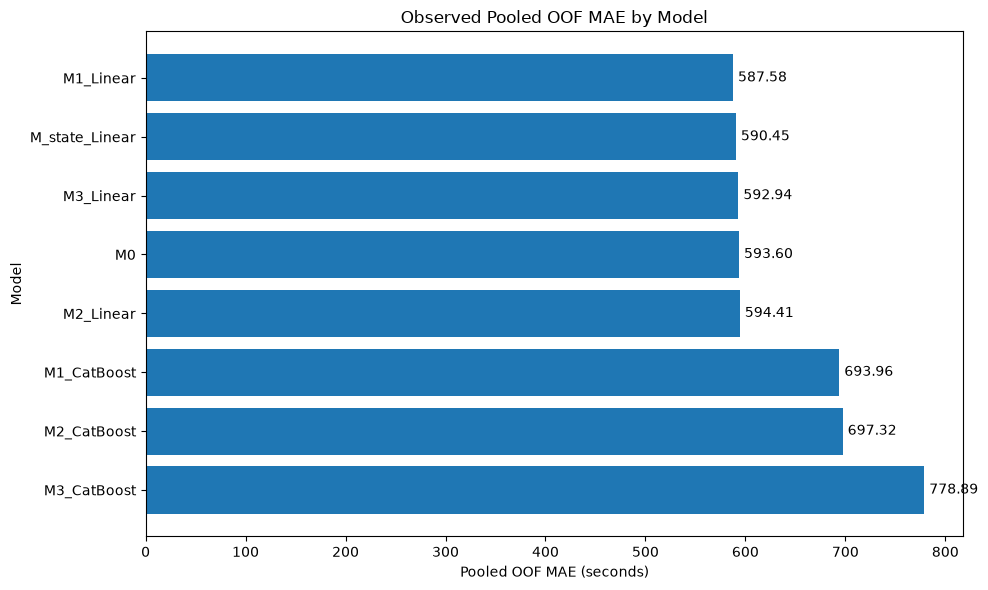

In [42]:
import matplotlib.pyplot as plt

# Add pooled M_state result to the existing pooled model results
m_state_eval = m_state_oof.copy()

m_state_eval["abs_error"] = (
    m_state_eval["y_true"] - m_state_eval["y_pred"]
).abs()

m_state_mae = m_state_eval["abs_error"].mean()

mae_plot = pd.concat([
    pooled_results[["model", "mae"]],
    pd.DataFrame({
        "model": ["M_state_Linear"],
        "mae": [m_state_mae],
    }),
]).sort_values("mae")

plt.figure(figsize=(10, 6))

bars = plt.barh(
    mae_plot["model"],
    mae_plot["mae"]
)

plt.xlabel("Pooled OOF MAE (seconds)")
plt.ylabel("Model")
plt.title("Observed Pooled OOF MAE by Model")

plt.gca().invert_yaxis()

for bar, value in zip(bars, mae_plot["mae"]):
    plt.text(
        value + 5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center",
    )

plt.tight_layout()
plt.show()

## Question 3: When does the selected model become unreliable?


In [43]:
call_type_mae = (
    dev_oof.loc[
        dev_oof["model"] == "M1_Linear"
    ]
    .assign(
        initial_call_type=lambda x: development.loc[
            x["row_index"],
            "initial_call_type"
        ].to_numpy(),
        abs_error=lambda x: (x["y_true"] - x["y_pred"]).abs(),
    )
    .groupby("initial_call_type", as_index=False)
    .agg(
        mae=("abs_error", "mean")
    )
    .sort_values("mae", ascending=False)
    .reset_index(drop=True)
)

call_type_mae.round(2)

,initial_call_type,mae
0,SPEVNT,10229.66
1,STNDBM,6548.70
2,STNDBY,6498.87
3,DOA,4532.48
4,STRANS,4067.25
5,EDPE,1714.73
6,MEDVAC,1552.83
7,INJMIN,1528.98
8,SICMIN,1485.16
9,HYPTN,1414.86


In [44]:
selected_oof = dev_oof.loc[
    dev_oof["model"] == "M1_Linear"
].copy()

selected_oof["initial_call_type"] = development.loc[
    selected_oof["row_index"],
    "initial_call_type"
].to_numpy()

selected_oof["error"] = (
    selected_oof["y_true"] - selected_oof["y_pred"]
)

selected_oof["abs_error"] = selected_oof["error"].abs()

call_type_errors = (
    selected_oof
    .groupby("initial_call_type", as_index=False)
    .agg(
        n=("abs_error", "size"),
        signed_error=("error", "mean"),
        mae=("abs_error", "mean"),
        p90=("abs_error", lambda x: x.quantile(0.90)),
    )
    .sort_values("mae", ascending=False)
    .reset_index(drop=True)
    .round(2)
)

call_type_errors

,initial_call_type,n,signed_error,mae,p90
0,SPEVNT,7,-8797.54,10229.66,21520.03
1,STNDBM,84,-2126.57,6548.70,15113.54
2,STNDBY,978,-897.09,6498.87,17012.66
3,DOA,5,-4532.48,4532.48,5561.71
4,STRANS,1,-4067.25,4067.25,4067.25
5,EDPE,240,-59.16,1714.73,2338.19
6,MEDVAC,1,1552.83,1552.83,1552.83
7,INJMIN,3295,-37.53,1528.98,2198.88
8,SICMIN,5438,6.34,1485.16,2198.93
9,HYPTN,741,-46.38,1414.86,1922.23


In [45]:
pd.set_option("display.max_rows", 200)

call_type_errors

,initial_call_type,n,signed_error,mae,p90
0,SPEVNT,7,-8797.54,10229.66,21520.03
1,STNDBM,84,-2126.57,6548.70,15113.54
2,STNDBY,978,-897.09,6498.87,17012.66
3,DOA,5,-4532.48,4532.48,5561.71
4,STRANS,1,-4067.25,4067.25,4067.25
5,EDPE,240,-59.16,1714.73,2338.19
6,MEDVAC,1,1552.83,1552.83,1552.83
7,INJMIN,3295,-37.53,1528.98,2198.88
8,SICMIN,5438,6.34,1485.16,2198.93
9,HYPTN,741,-46.38,1414.86,1922.23


In [46]:
overall_mae = selected_oof["abs_error"].mean()

min_n = int(0.001 * len(selected_oof))

failure_mae_threshold = 2 * overall_mae

failure_types = call_type_errors.loc[
    call_type_errors["mae"] >= failure_mae_threshold
].copy()

systematic_failures = (
    failure_types.loc[
        failure_types["n"] >= min_n
    ]
    .sort_values("mae", ascending=False)
    .reset_index(drop=True)
)

rare_type_failures = (
    failure_types.loc[
        failure_types["n"] < min_n
    ]
    .sort_values("mae", ascending=False)
    .reset_index(drop=True)
)

print(
    f"Failure threshold: {failure_mae_threshold:.2f} sec "
    f"({failure_mae_threshold / 60:.1f} min)"
)

print(f"Minimum n for systematic failure: {min_n}")

print("\nSYSTEMATIC FAILURE REGIMES")
display(systematic_failures)

print("\nRARE-TYPE FAILURE REGIMES")
display(rare_type_failures)

Failure threshold: 1175.16 sec (19.6 min)
Minimum n for systematic failure: 390

SYSTEMATIC FAILURE REGIMES


,initial_call_type,n,signed_error,mae,p90
0,STNDBY,978,-897.09,6498.87,17012.66
1,INJMIN,3295,-37.53,1528.98,2198.88
2,SICMIN,5438,6.34,1485.16,2198.93
3,HYPTN,741,-46.38,1414.86,1922.23



RARE-TYPE FAILURE REGIMES


,initial_call_type,n,signed_error,mae,p90
0,SPEVNT,7,-8797.54,10229.66,21520.03
1,STNDBM,84,-2126.57,6548.70,15113.54
2,DOA,5,-4532.48,4532.48,5561.71
3,STRANS,1,-4067.25,4067.25,4067.25
4,EDPE,240,-59.16,1714.73,2338.19
5,MEDVAC,1,1552.83,1552.83,1552.83


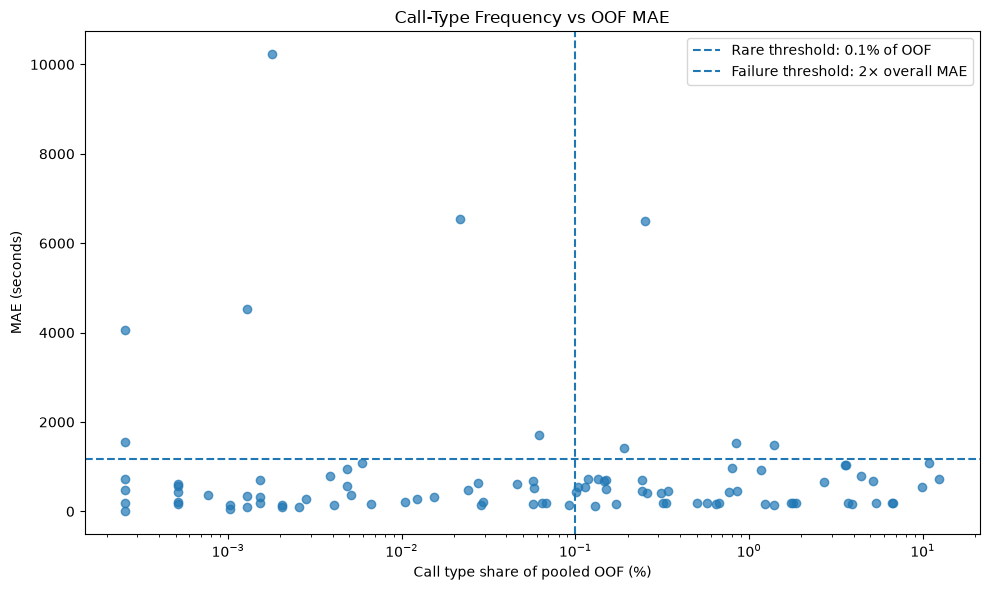

In [47]:
import matplotlib.pyplot as plt

plot_df = call_type_errors.copy()

plot_df["share_pct"] = (
    100 * plot_df["n"] / len(selected_oof)
)

rare_threshold_pct = 0.1
failure_threshold = 2 * overall_mae

plt.figure(figsize=(10, 6))

plt.scatter(
    plot_df["share_pct"],
    plot_df["mae"],
    alpha=0.7
)

plt.axvline(
    rare_threshold_pct,
    linestyle="--",
    label="Rare threshold: 0.1% of OOF"
)

plt.axhline(
    failure_threshold,
    linestyle="--",
    label="Failure threshold: 2× overall MAE"
)

plt.xscale("log")

plt.xlabel("Call type share of pooled OOF (%)")
plt.ylabel("MAE (seconds)")
plt.title("Call-Type Frequency vs OOF MAE")

plt.legend()
plt.tight_layout()
plt.show()

In [48]:
call_type_response = (
    selected_oof
    .groupby("initial_call_type", as_index=False)
    .agg(
        n=("y_true", "size"),
        mean_response_seconds=("y_true", "mean"),
        median_response_seconds=("y_true", "median"),
    )
    .sort_values("mean_response_seconds", ascending=False)
    .reset_index(drop=True)
)

call_type_response["mean_response_minutes"] = (
    call_type_response["mean_response_seconds"] / 60
)

call_type_response["median_response_minutes"] = (
    call_type_response["median_response_seconds"] / 60
)

call_type_response.round(2)

,initial_call_type,n,mean_response_seconds,median_response_seconds,mean_response_minutes,median_response_minutes
0,STNDBM,84,13805.67,16477.5,230.09,274.62
1,SPEVNT,7,12695.43,18393.0,211.59,306.55
2,STNDBY,978,4157.72,609.0,69.30,10.15
3,MEDVAC,1,2367.00,2367.0,39.45,39.45
4,EDPE,240,2037.71,1056.5,33.96,17.61
5,SICMIN,5438,1840.04,988.5,30.67,16.48
6,INJMIN,3295,1807.70,957.0,30.13,15.95
7,HYPTN,741,1732.64,937.0,28.88,15.62
8,EDP,14061,1547.50,1011.0,25.79,16.85
9,T-EDP,19,1517.79,870.0,25.30,14.50


In [49]:
response_rank = (
    call_type_response
    .sort_values("mean_response_seconds", ascending=False)
    .reset_index(drop=True)
    .copy()
)

response_rank["response_time_rank"] = response_rank.index + 1

failure_rank_table = pd.concat([
    systematic_failures.assign(
        failure_type="Systematic"
    ),
    rare_type_failures.assign(
        failure_type="Rare"
    ),
])[
    [
        "initial_call_type",
        "failure_type",
        "mae",
    ]
].merge(
    response_rank[
        [
            "initial_call_type",
            "response_time_rank",
            "mean_response_minutes",
            "median_response_minutes",
        ]
    ],
    on="initial_call_type",
    how="left",
)

failure_rank_table = (
    failure_rank_table
    .sort_values("response_time_rank")
    .reset_index(drop=True)
    .round(2)
)

failure_rank_table

,initial_call_type,failure_type,mae,response_time_rank,mean_response_minutes,median_response_minutes
0,STNDBM,Rare,6548.70,1,230.09,274.62
1,SPEVNT,Rare,10229.66,2,211.59,306.55
2,STNDBY,Systematic,6498.87,3,69.30,10.15
3,MEDVAC,Rare,1552.83,4,39.45,39.45
4,EDPE,Rare,1714.73,5,33.96,17.61
5,SICMIN,Systematic,1485.16,6,30.67,16.48
6,INJMIN,Systematic,1528.98,7,30.13,15.95
7,HYPTN,Systematic,1414.86,8,28.88,15.62
8,DOA,Rare,4532.48,48,10.45,9.20
9,STRANS,Rare,4067.25,93,3.13,3.13


In [50]:
response_time_error = selected_oof[
    ["y_true", "abs_error"]
].copy()

response_time_error["response_minutes"] = (
    response_time_error["y_true"] / 60
)

response_time_error["response_time_range"] = pd.qcut(
    response_time_error["response_minutes"],
    q=10,
    duplicates="drop"
)

response_time_range_table = (
    response_time_error
    .groupby(
        "response_time_range",
        observed=True,
        as_index=False
    )
    .agg(
        n=("abs_error", "size"),
        mae_seconds=("abs_error", "mean"),
    )
)

response_time_range_table["mae_minutes"] = (
    response_time_range_table["mae_seconds"] / 60
)

response_time_range_table.round(2)

,response_time_range,n,mae_seconds,mae_minutes
0,"(-0.001, 4.233]",39103,589.91,9.83
1,"(4.233, 5.583]",39296,405.29,6.75
2,"(5.583, 6.733]",39104,362.98,6.05
3,"(6.733, 7.9]",38897,347.65,5.79
4,"(7.9, 9.233]",38756,358.97,5.98
5,"(9.233, 10.9]",39085,379.95,6.33
6,"(10.9, 13.267]",39096,383.76,6.40
7,"(13.267, 17.4]",38944,332.16,5.54
8,"(17.4, 28.017]",38974,343.45,5.72
9,"(28.017, 539.733]",39016,2371.31,39.52


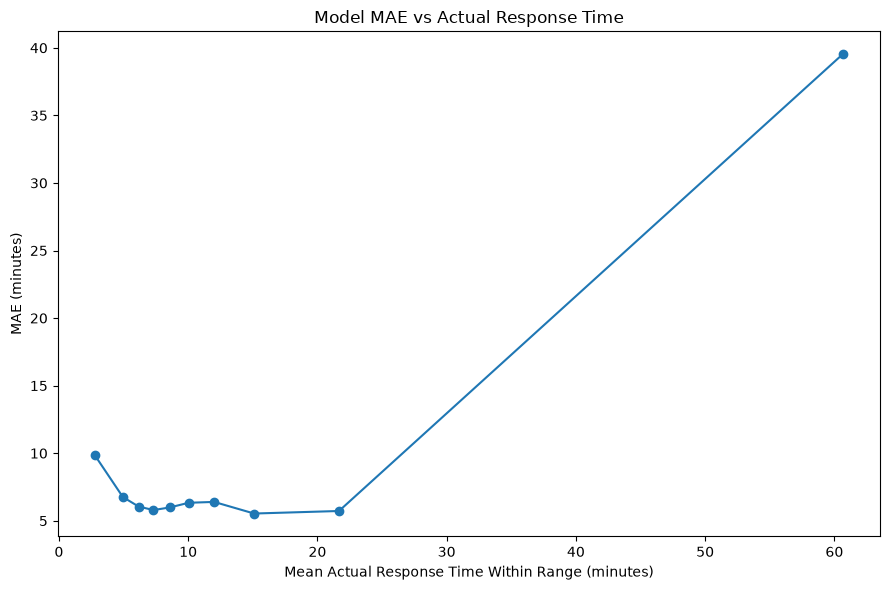

In [51]:
import matplotlib.pyplot as plt

plot_df = (
    response_time_error
    .groupby(
        "response_time_range",
        observed=True,
        as_index=False
    )
    .agg(
        mean_response_minutes=("response_minutes", "mean"),
        mae_seconds=("abs_error", "mean"),
    )
)

plot_df["mae_minutes"] = (
    plot_df["mae_seconds"] / 60
)

plt.figure(figsize=(9, 6))

plt.plot(
    plot_df["mean_response_minutes"],
    plot_df["mae_minutes"],
    marker="o"
)

plt.xlabel("Mean Actual Response Time Within Range (minutes)")
plt.ylabel("MAE (minutes)")
plt.title("Model MAE vs Actual Response Time")

plt.tight_layout()
plt.show()

In [52]:
response_p90 = selected_oof["y_true"].quantile(0.90)

full_mae = selected_oof["abs_error"].mean()

trimmed_oof = selected_oof.loc[
    selected_oof["y_true"] <= response_p90
].copy()

trimmed_mae = trimmed_oof["abs_error"].mean()

tail_mae_comparison = pd.DataFrame({
    "sample": [
        "All OOF incidents",
        "Remove longest 10% of response times",
    ],
    "mae_seconds": [
        full_mae,
        trimmed_mae,
    ],
    "mae_minutes": [
        full_mae / 60,
        trimmed_mae / 60,
    ],
})

print(
    f"90th percentile response-time cutoff: "
    f"{response_p90:.2f} sec ({response_p90 / 60:.2f} min)"
)

tail_mae_comparison.round(2)

90th percentile response-time cutoff: 1681.00 sec (28.02 min)


,sample,mae_seconds,mae_minutes
0,All OOF incidents,587.58,9.79
1,Remove longest 10% of response times,389.45,6.49


In [53]:
severity_errors = selected_oof.copy()

severity_errors["initial_severity_level_code"] = development.loc[
    severity_errors["row_index"],
    "initial_severity_level_code"
].to_numpy()

severity_mae_table = (
    severity_errors
    .groupby(
        "initial_severity_level_code",
        as_index=False
    )
    .agg(
        n=("abs_error", "size"),
        mae_seconds=("abs_error", "mean"),
    )
    .sort_values(
        "initial_severity_level_code"
    )
    .reset_index(drop=True)
)

severity_mae_table["mae_minutes"] = (
    severity_mae_table["mae_seconds"] / 60
)

severity_mae_table.round(2)

,initial_severity_level_code,n,mae_seconds,mae_minutes
0,1,5951,140.99,2.35
1,2,84459,177.02,2.95
2,3,58808,187.59,3.13
3,4,53178,523.98,8.73
4,5,98436,716.09,11.93
5,6,47371,1064.51,17.74
6,7,41002,1139.86,19.00
7,8,1065,6550.33,109.17
8,9,1,732.06,12.20


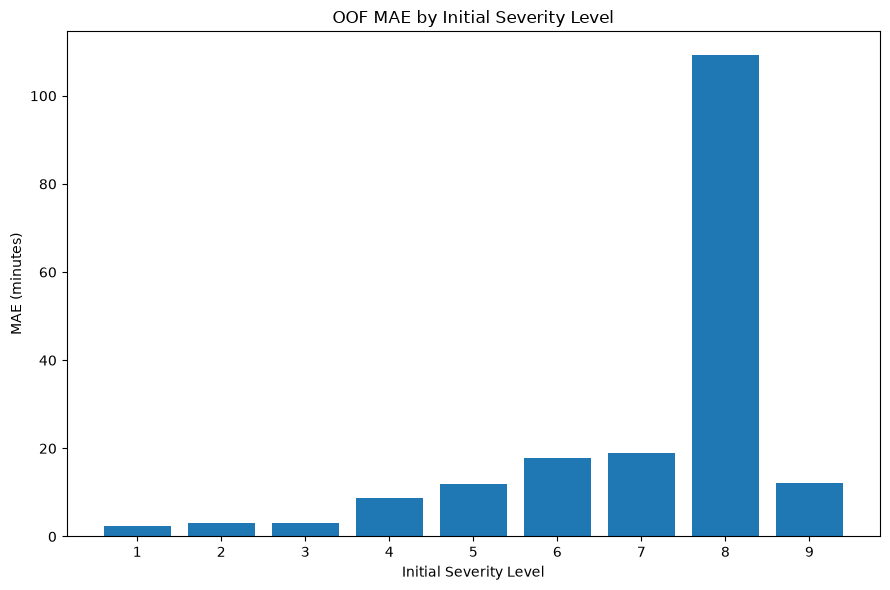

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.bar(
    severity_mae_table["initial_severity_level_code"].astype(str),
    severity_mae_table["mae_minutes"],
)

plt.xlabel("Initial Severity Level")
plt.ylabel("MAE (minutes)")
plt.title("OOF MAE by Initial Severity Level")

plt.tight_layout()
plt.show()

In [55]:
severity_response_mae = (
    severity_errors
    .groupby(
        "initial_severity_level_code",
        as_index=False
    )
    .agg(
        n=("y_true", "size"),
        mean_response_seconds=("y_true", "mean"),
        mae_seconds=("abs_error", "mean"),
    )
    .sort_values("initial_severity_level_code")
    .reset_index(drop=True)
)

severity_response_mae.round(2)

,initial_severity_level_code,n,mean_response_seconds,mae_seconds
0,1,5951,377.46,140.99
1,2,84459,472.15,177.02
2,3,58808,480.95,187.59
3,4,53178,876.76,523.98
4,5,98436,1017.53,716.09
5,6,47371,1310.06,1064.51
6,7,41002,1578.77,1139.86
7,8,1065,4981.28,6550.33
8,9,1,0.00,732.06


In [56]:
temporal_errors = selected_oof.copy()

temporal_errors["month"] = development.loc[
    temporal_errors["row_index"],
    "month"
].to_numpy()

temporal_errors["day_of_week"] = development.loc[
    temporal_errors["row_index"],
    "day_of_week"
].to_numpy()

temporal_errors["season"] = temporal_errors["month"].map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Fall", 10: "Fall", 11: "Fall",
})

In [57]:
month_response_mae = (
    temporal_errors
    .groupby("month", as_index=False)
    .agg(
        n=("y_true", "size"),
        mean_response_seconds=("y_true", "mean"),
        mae_seconds=("abs_error", "mean"),
    )
    .sort_values("month")
    .reset_index(drop=True)
)

month_response_mae.round(2)

,month,n,mean_response_seconds,mae_seconds
0,7,135109,894.28,599.61
1,8,129112,859.13,560.80
2,9,126050,932.50,602.12


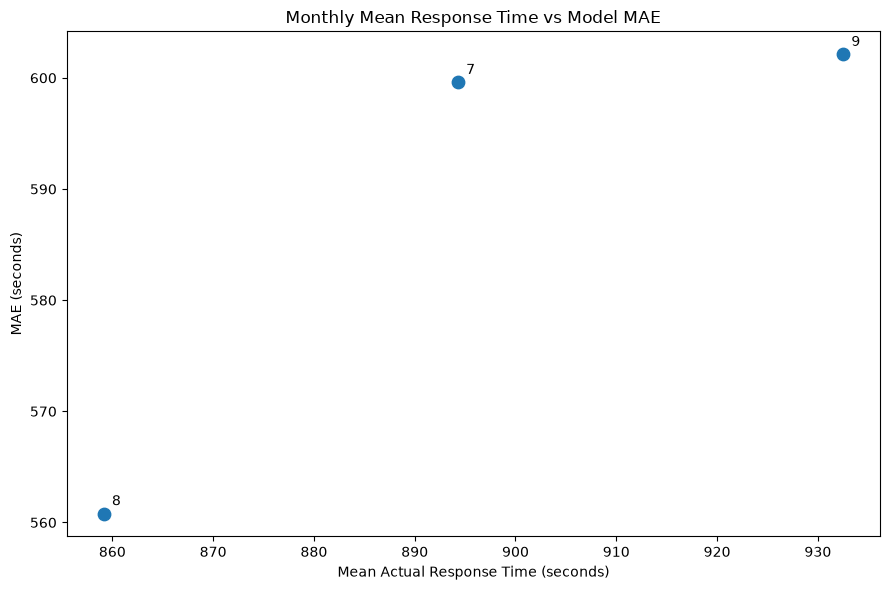

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    month_response_mae["mean_response_seconds"],
    month_response_mae["mae_seconds"],
    s=80,
)

for _, row in month_response_mae.iterrows():
    plt.annotate(
        str(int(row["month"])),
        (
            row["mean_response_seconds"],
            row["mae_seconds"],
        ),
        xytext=(6, 6),
        textcoords="offset points",
    )

plt.xlabel("Mean Actual Response Time (seconds)")
plt.ylabel("MAE (seconds)")
plt.title("Monthly Mean Response Time vs Model MAE")

plt.tight_layout()
plt.show()

In [59]:
day_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday",
}

day_response_mae = (
    temporal_errors
    .groupby("day_of_week", as_index=False)
    .agg(
        n=("y_true", "size"),
        mean_response_seconds=("y_true", "mean"),
        mae_seconds=("abs_error", "mean"),
    )
    .sort_values("day_of_week")
    .reset_index(drop=True)
)

day_response_mae["day"] = (
    day_response_mae["day_of_week"].map(day_names)
)

day_response_mae[
    [
        "day",
        "n",
        "mean_response_seconds",
        "mae_seconds",
    ]
].round(2)

,day,n,mean_response_seconds,mae_seconds
0,Monday,61075,961.54,640.21
1,Tuesday,55141,846.44,573.46
2,Wednesday,55274,901.41,598.41
3,Thursday,55285,908.10,599.31
4,Friday,56665,941.50,611.82
5,Saturday,53981,841.84,533.44
6,Sunday,52850,852.76,547.22


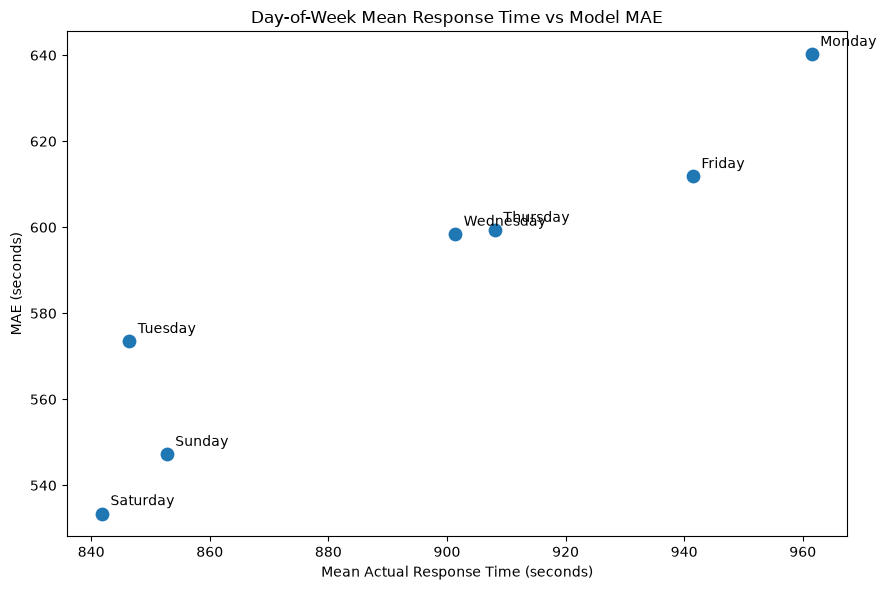

In [60]:
plt.figure(figsize=(9, 6))

plt.scatter(
    day_response_mae["mean_response_seconds"],
    day_response_mae["mae_seconds"],
    s=80,
)

for _, row in day_response_mae.iterrows():
    plt.annotate(
        row["day"],
        (
            row["mean_response_seconds"],
            row["mae_seconds"],
        ),
        xytext=(6, 6),
        textcoords="offset points",
    )

plt.xlabel("Mean Actual Response Time (seconds)")
plt.ylabel("MAE (seconds)")
plt.title("Day-of-Week Mean Response Time vs Model MAE")

plt.tight_layout()
plt.show()

## Question 4: Can predictive uncertainty inform operational review?


## Distribution shift

Categorical total variation and numerical Wasserstein diagnostics test whether development and holdout populations differ. Drift is a warning to investigate model validity, not itself proof of performance deterioration.


In [61]:
drift_features = feature_sets["M1"]

categorical_drift_cols = [
    col for col in CATEGORICAL_COLS
    if col in drift_features
]

numerical_drift_cols = [
    col for col in drift_features
    if col not in categorical_drift_cols
]

print("Categorical:")
print(categorical_drift_cols)

print("\nNumerical:")
print(numerical_drift_cols)

Categorical:
['initial_call_type', 'initial_severity_level_code', 'day_of_week', 'month']

Numerical:
['year', 'season_sin', 'season_cos']


In [62]:
categorical_drift_cols = [
    "initial_call_type",
    "initial_severity_level_code",
]

def total_variation_distance(dev, hold):
    dev = dev.fillna("__MISSING__").astype(str)
    hold = hold.fillna("__MISSING__").astype(str)

    categories = pd.Index(
        dev.unique().tolist()
        + hold.unique().tolist()
    ).unique()

    p = (
        dev.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
    )

    q = (
        hold.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
    )

    return 0.5 * np.abs(p - q).sum()


categorical_drift = pd.DataFrame({
    "feature": categorical_drift_cols,
    "tvd": [
        total_variation_distance(
            development[col],
            holdout[col],
        )
        for col in categorical_drift_cols
    ],
})

categorical_drift.round(4)

,feature,tvd
0,initial_call_type,0.0235
1,initial_severity_level_code,0.0146


In [63]:
from scipy.stats import wasserstein_distance

response_col = "incident_response_seconds_qy"

dev_response = development[response_col].dropna()
holdout_response = holdout[response_col].dropna()

train_mean = dev_response.mean()
train_std = dev_response.std()

dev_scaled = (
    dev_response - train_mean
) / train_std

holdout_scaled = (
    holdout_response - train_mean
) / train_std

response_time_wasserstein = wasserstein_distance(
    dev_scaled,
    holdout_scaled,
)

pd.DataFrame({
    "feature": [response_col],
    "standardized_wasserstein": [
        response_time_wasserstein
    ],
}).round(4)

,feature,standardized_wasserstein
0,incident_response_seconds_qy,0.042


In [64]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

features = feature_sets["M1"]

cat_cols = [
    col for col in CATEGORICAL_COLS
    if col in features
]

num_cols = [
    col for col in features
    if col not in cat_cols
]

X_dev = development[features].copy()
y_dev = development[TARGET]

X_holdout = holdout[features].copy()
y_holdout = holdout[TARGET]

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value=-1,
        ),
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
        ),
    ),
])

preprocess = ColumnTransformer([
    ("categorical", categorical_pipeline, cat_cols),
    ("numeric", "passthrough", num_cols),
])

final_m1 = Pipeline([
    ("preprocess", preprocess),
    ("model", LinearRegression()),
])

final_m1.fit(X_dev, y_dev)

holdout_pred = final_m1.predict(X_holdout)

holdout_mae = mean_absolute_error(
    y_holdout,
    holdout_pred,
)

print(f"Holdout MAE: {holdout_mae:.2f} seconds")

Holdout MAE: 541.42 seconds


In [65]:
# Fit M0 on development only
m0_group_means = (
    development
    .groupby(m0_group_cols)[TARGET]
    .mean()
)

development_global_mean = development[TARGET].mean()

# Predict holdout
holdout_keys = pd.MultiIndex.from_frame(
    holdout[m0_group_cols]
)

m0_holdout_pred = (
    m0_group_means
    .reindex(holdout_keys)
    .to_numpy()
)

m0_holdout_pred = np.where(
    pd.isna(m0_holdout_pred),
    development_global_mean,
    m0_holdout_pred,
)

# MAE
m0_holdout_mae = mean_absolute_error(
    y_holdout,
    m0_holdout_pred,
)

comparison = pd.DataFrame({
    "model": ["M0", "M1_Linear"],
    "holdout_mae": [
        m0_holdout_mae,
        holdout_mae,
    ],
})

comparison.round(2)

,model,holdout_mae
0,M0,553.84
1,M1_Linear,541.42


In [66]:
holdout_gain = pd.DataFrame({
    "day": holdout["incident_datetime"].dt.normalize().to_numpy(),
    "m0_abs_error": np.abs(
        y_holdout.to_numpy() - m0_holdout_pred
    ),
    "m1_abs_error": np.abs(
        y_holdout.to_numpy() - holdout_pred
    ),
})

holdout_gain["gain"] = (
    holdout_gain["m0_abs_error"]
    - holdout_gain["m1_abs_error"]
)

daily_gain = (
    holdout_gain
    .groupby("day")["gain"]
    .agg(["sum", "count"])
)

rng = np.random.default_rng(42)

block_sums = daily_gain["sum"].to_numpy()
block_counts = daily_gain["count"].to_numpy()

n_days = len(daily_gain)
n_boot = 10_000

boot_gains = np.empty(n_boot)

for b in range(n_boot):
    sampled_days = rng.integers(
        0,
        n_days,
        size=n_days,
    )

    boot_gains[b] = (
        block_sums[sampled_days].sum()
        / block_counts[sampled_days].sum()
    )

observed_gain = holdout_gain["gain"].mean()

ci_low, ci_high = np.quantile(
    boot_gains,
    [0.025, 0.975]
)

bootstrap_gain_results = pd.DataFrame({
    "observed_gain_seconds": [observed_gain],
    "ci_95_lower": [ci_low],
    "ci_95_upper": [ci_high],
    "spans_zero": [
        ci_low <= 0 <= ci_high
    ],
})

bootstrap_gain_results.round(2)

,observed_gain_seconds,ci_95_lower,ci_95_upper,spans_zero
0,12.41,7.37,17.49,False


## Predictive uncertainty: CQR

Chronological fitting and calibration construct nominal 90% intervals. The later holdout measures their actual coverage. Undercoverage is an empirical limitation, not evidence of guaranteed operational protection. Zero is the lower response-time bound because the retained source includes zero-second outcomes.


In [67]:
cqr_calibration_start = (
    development["incident_datetime"].max()
    - pd.DateOffset(months=1)
)

cqr_train = development.loc[
    development["incident_datetime"] < cqr_calibration_start
].copy()

cqr_calibration = development.loc[
    development["incident_datetime"] >= cqr_calibration_start
].copy()

In [68]:
from catboost import CatBoostRegressor

cqr_features = feature_sets["M1"]

cqr_cat_cols = [
    col for col in CATEGORICAL_COLS
    if col in cqr_features
]

X_cqr_train = cqr_train[cqr_features].copy()
y_cqr_train = cqr_train[TARGET]

# Prepare categorical columns for CatBoost
for col in cqr_cat_cols:
    X_cqr_train[col] = (
        X_cqr_train[col]
        .fillna(-1)
        .astype(str)
    )

# Lower 5% quantile
q_lo_model = CatBoostRegressor(
    loss_function="Quantile:alpha=0.05",
    verbose=False,
    random_seed=42,
    allow_writing_files=False,
)

# Upper 95% quantile
q_hi_model = CatBoostRegressor(
    loss_function="Quantile:alpha=0.95",
    verbose=False,
    random_seed=42,
    allow_writing_files=False,
)

q_lo_model.fit(
    X_cqr_train,
    y_cqr_train,
    cat_features=cqr_cat_cols,
)

q_hi_model.fit(
    X_cqr_train,
    y_cqr_train,
    cat_features=cqr_cat_cols,
)

print("q05 and q95 models fitted.")

q05 and q95 models fitted.


In [69]:
X_cqr_calibration = cqr_calibration[cqr_features].copy()

for col in cqr_cat_cols:
    X_cqr_calibration[col] = (
        X_cqr_calibration[col]
        .fillna(-1)
        .astype(str)
    )

calibration_q_lo = q_lo_model.predict(
    X_cqr_calibration
)

calibration_q_hi = q_hi_model.predict(
    X_cqr_calibration
)

cqr_calibration_predictions = pd.DataFrame({
    "y_true": cqr_calibration[TARGET].to_numpy(),
    "q_lo": np.minimum(calibration_q_lo, calibration_q_hi),
    "q_hi": np.maximum(calibration_q_lo, calibration_q_hi),
})

cqr_calibration_predictions.head()

,y_true,q_lo,q_hi
0,557.0,195.509587,3267.624762
1,204.0,209.023691,2288.844346
2,565.0,237.631574,3389.325422
3,671.0,191.071106,951.122995
4,448.0,220.180925,4438.271027


In [70]:
def conformal_radius(scores, alpha=0.10):
    scores = np.asarray(scores, dtype=float)
    if scores.ndim != 1 or len(scores) == 0 or not np.isfinite(scores).all():
        raise ValueError("Calibration scores must be a nonempty finite vector.")
    if not 0 < alpha < 1:
        raise ValueError("alpha must lie strictly between 0 and 1.")
    rank = int(np.ceil((len(scores) + 1) * (1 - alpha)))
    if rank > len(scores):
        return np.inf
    return float(np.partition(scores, rank - 1)[rank - 1])

alpha = 0.10
cqr_calibration_predictions["score"] = np.maximum(
    cqr_calibration_predictions["q_lo"] - cqr_calibration_predictions["y_true"],
    cqr_calibration_predictions["y_true"] - cqr_calibration_predictions["q_hi"],
)
scores = cqr_calibration_predictions["score"].to_numpy()
q_hat = conformal_radius(scores, alpha)
print(f"q_hat: {q_hat:.2f} seconds")


q_hat: 396.03 seconds


In [71]:
X_cqr_holdout = holdout[cqr_features].copy()

for col in cqr_cat_cols:
    X_cqr_holdout[col] = (
        X_cqr_holdout[col]
        .fillna(-1)
        .astype(str)
    )

holdout_q_lo = q_lo_model.predict(
    X_cqr_holdout
)

holdout_q_hi = q_hi_model.predict(
    X_cqr_holdout
)

cqr_holdout_predictions = pd.DataFrame({
    "y_true": holdout[TARGET].to_numpy(),
    "q_lo_raw": np.minimum(holdout_q_lo, holdout_q_hi),
    "q_hi_raw": np.maximum(holdout_q_lo, holdout_q_hi),
})

cqr_holdout_predictions["lower"] = np.maximum(
    cqr_holdout_predictions["q_lo_raw"] - q_hat,
    0,
)

cqr_holdout_predictions["upper"] = (
    cqr_holdout_predictions["q_hi_raw"] + q_hat
)

cqr_holdout_predictions.head()

,y_true,q_lo_raw,q_hi_raw,lower,upper
0,232.0,-547.668877,304.780807,0.000000,700.810295
1,466.0,-157.951825,325.678814,0.000000,721.708302
2,305.0,474.364624,1861.043204,78.335136,2257.072692
3,451.0,511.958498,1402.573551,115.929009,1798.603039
4,381.0,-159.501157,303.335724,0.000000,699.365213


In [72]:
covered = (
    (cqr_holdout_predictions["y_true"]
     >= cqr_holdout_predictions["lower"])
    &
    (cqr_holdout_predictions["y_true"]
     <= cqr_holdout_predictions["upper"])
)

holdout_coverage = covered.mean()

print(f"Holdout coverage: {holdout_coverage:.2%}")
print("Target coverage: 90.00%")

Holdout coverage: 84.45%
Target coverage: 90.00%


In [73]:
cqr_holdout_predictions["interval_width"] = (
    cqr_holdout_predictions["upper"]
    - cqr_holdout_predictions["lower"]
)

cqr_holdout_predictions[
    ["y_true", "lower", "upper", "interval_width"]
].head()

,y_true,lower,upper,interval_width
0,232.0,0.000000,700.810295,700.810295
1,466.0,0.000000,721.708302,721.708302
2,305.0,78.335136,2257.072692,2178.737557
3,451.0,115.929009,1798.603039,1682.674030
4,381.0,0.000000,699.365213,699.365213


In [74]:
review_fraction = 0.15

cqr_holdout_predictions["point_pred"] = holdout_pred

cqr_holdout_predictions["uncertainty_rank"] = (
    cqr_holdout_predictions["interval_width"]
    .rank(method="first", ascending=False)
)

n_review = int(
    np.ceil(
        review_fraction
        * len(cqr_holdout_predictions)
    )
)

cqr_holdout_predictions["human_review"] = (
    cqr_holdout_predictions["uncertainty_rank"]
    <= n_review
)

automatic_predictions = (
    cqr_holdout_predictions.loc[
        ~cqr_holdout_predictions["human_review"]
    ]
    .copy()
)

automatic_mae = mean_absolute_error(
    automatic_predictions["y_true"],
    automatic_predictions["point_pred"],
)

automatic_coverage = (
    (
        automatic_predictions["y_true"]
        >= automatic_predictions["lower"]
    )
    &
    (
        automatic_predictions["y_true"]
        <= automatic_predictions["upper"]
    )
).mean()

print(f"Automatic coverage: {len(automatic_predictions) / len(cqr_holdout_predictions):.2%}")
print(f"MAE on automatic predictions: {automatic_mae:.2f} seconds")
print(f"CQR interval coverage: {automatic_coverage:.2%}")

Automatic coverage: 85.00%
MAE on automatic predictions: 450.02 seconds
CQR interval coverage: 84.12%


In [75]:
# Diagnose the rejected joint call-type/severity specification without
# reporting non-identifiable coefficients as interpretable associations.
from patsy import dmatrix

joint_terms = ["initial_call_type", "initial_severity_level_code", "day_of_week", "month"]
joint_design = dmatrix(
    "C(initial_call_type) + C(initial_severity_level_code) + C(day_of_week) + C(month)",
    history_features[joint_terms].drop_duplicates(),
    return_type="dataframe",
)
joint_design_rank = np.linalg.matrix_rank(joint_design.to_numpy())
joint_design_columns = joint_design.shape[1]
print(f"Joint specification: rank {joint_design_rank} / {joint_design_columns} columns")
print("Rejected for coefficient interpretation: the joint design is rank-deficient.")
print("The following analysis uses severity, weekday, and month; it does not adjust for call type.")
del joint_design


Joint specification: rank 123 / 124 columns
Rejected for coefficient interpretation: the joint design is rank-deficient.
The following analysis uses severity, weekday, and month; it does not adjust for call type.


In [76]:
severity_by_call_type = (
    history_features
    .groupby("initial_call_type")["initial_severity_level_code"]
    .nunique()
    .value_counts()
    .sort_index()
)

severity_by_call_type

initial_severity_level_code
1    41
2    19
3     9
4     8
5     6
6    12
7     8
8     1
Name: count, dtype: int64

In [77]:
import statsmodels.formula.api as smf

ols_formula = """
incident_response_seconds_qy
~ C(initial_severity_level_code)
+ C(day_of_week)
+ C(month)
"""

ols_model = smf.ols(
    formula=ols_formula,
    data=history_features,
).fit(cov_type="HC3")

assert ols_model.model.rank == ols_model.model.exog.shape[1]
assert np.isfinite(ols_model.params).all()
assert np.isfinite(ols_model.conf_int()).all().all()

ols_results = (
    pd.DataFrame({
        "coefficient": ols_model.params,
        "ci_low": ols_model.conf_int()[0],
        "ci_high": ols_model.conf_int()[1],
        "p_value": ols_model.pvalues,
    })
    .drop(index="Intercept")
    .sort_values("coefficient")
    .round(2)
)

ols_results

,coefficient,ci_low,ci_high,p_value
C(initial_severity_level_code)[T.9],-328.08,-440.13,-216.03,0.00
C(month)[T.11],-184.78,-195.22,-174.33,0.00
C(month)[T.8],-123.03,-132.70,-113.36,0.00
C(day_of_week)[T.6],-114.74,-124.49,-105.00,0.00
C(month)[T.10],-107.87,-117.63,-98.11,0.00
C(day_of_week)[T.5],-106.56,-116.29,-96.84,0.00
C(month)[T.6],-90.17,-100.07,-80.28,0.00
C(month)[T.7],-85.78,-95.75,-75.82,0.00
C(day_of_week)[T.1],-68.16,-78.34,-57.98,0.00
C(month)[T.9],-49.57,-60.00,-39.13,0.00


In [78]:
from statsmodels.stats.diagnostic import acorr_ljungbox

residual_data = pd.DataFrame({
    "incident_datetime": history_features["incident_datetime"],
    "residual": ols_model.resid,
})

daily_residuals = (
    residual_data
    .set_index("incident_datetime")["residual"]
    .resample("D")
    .mean()
    .dropna()
)

ljung_box = acorr_ljungbox(
    daily_residuals,
    lags=range(1, 8),
    return_df=True,
)

residual_continuity = pd.DataFrame({
    "lag_days": range(1, 8),
    "autocorrelation": [
        daily_residuals.autocorr(lag=lag)
        for lag in range(1, 8)
    ],
    "p_value": ljung_box["lb_pvalue"].to_numpy(),
}).round(4)

residual_continuity

,lag_days,autocorrelation,p_value
0,1,0.2707,0.0001
1,2,0.0628,0.0004
2,3,-0.0266,0.0012
3,4,0.0841,0.0017
4,5,0.0270,0.0038
5,6,0.0340,0.0072
6,7,-0.0381,0.0122


## Residual regime exploration: HMM

A two-state Gaussian hidden Markov model is fitted to daily aggregated development residuals. The estimated state can inform a sequential forecast correction, but this experiment uses in-sample development residuals and was added after seeing the existing holdout; it requires a fresh prospective test.


In [79]:
dev_pred = final_m1.predict(
    development[features]
)

dev_daily_residuals = (
    pd.DataFrame({
        "day": development[
            "incident_datetime"
        ].dt.normalize().to_numpy(),

        "residual": (
            development[TARGET].to_numpy()
            - dev_pred
        ),
    })
    .groupby("day")["residual"]
    .mean()
    .sort_index()
)

dev_daily_residuals.head()

day
2024-05-01     97.814695
2024-05-02     55.807684
2024-05-03    -41.494054
2024-05-04    -94.585212
2024-05-05   -140.427924
Name: residual, dtype: float64

In [80]:
from hmmlearn.hmm import GaussianHMM

hmm_train = (
    dev_daily_residuals
    .to_numpy()
    .reshape(-1, 1)
)

hmm_model = GaussianHMM(
    n_components=2,
    covariance_type="diag",
    n_iter=1000,
    random_state=42,
)

hmm_model.fit(hmm_train)

state_means = (
    pd.Series(
        hmm_model.means_.ravel(),
        name="mean_residual_seconds",
    )
    .sort_values()
)

state_means

0   -125.630992
1     46.967554
Name: mean_residual_seconds, dtype: float64

In [81]:
holdout_hmm = pd.DataFrame({
    "day": (
        holdout["incident_datetime"]
        .dt.normalize()
        .to_numpy()
    ),
    "y_true": y_holdout.to_numpy(),
    "m1_pred": holdout_pred,
})

holdout_hmm["hmm_pred"] = np.nan

observed_daily_residuals = (
    dev_daily_residuals
    .to_numpy()
    .tolist()
)

for day in sorted(holdout_hmm["day"].unique()):

    observed_sequence = np.asarray(
        observed_daily_residuals
    ).reshape(-1, 1)

    # State probabilities using information
    # available only through the previous day
    current_state_prob = (
        hmm_model
        .predict_proba(observed_sequence)[-1]
    )

    # Predict tomorrow's state probabilities
    next_state_prob = (
        current_state_prob
        @ hmm_model.transmat_
    )

    # Expected residual for the coming day
    residual_adjustment = (
        next_state_prob
        @ hmm_model.means_.ravel()
    )

    day_mask = (
        holdout_hmm["day"] == day
    )

    holdout_hmm.loc[
        day_mask,
        "hmm_pred"
    ] = (
        holdout_hmm.loc[
            day_mask,
            "m1_pred"
        ]
        + residual_adjustment
    )

    # Only after that day's predictions are made
    # do we observe that day's realized M1 residual
    day_residual = (
        holdout_hmm.loc[
            day_mask,
            "y_true"
        ]
        - holdout_hmm.loc[
            day_mask,
            "m1_pred"
        ]
    ).mean()

    observed_daily_residuals.append(
        day_residual
    )

In [82]:
hmm_holdout_mae = mean_absolute_error(
    holdout_hmm["y_true"],
    holdout_hmm["hmm_pred"],
)

hmm_comparison = pd.DataFrame({
    "model": [
        "M1",
        "M1 + HMM",
    ],
    "holdout_mae_seconds": [
        holdout_mae,
        hmm_holdout_mae,
    ],
})

hmm_comparison.round(2)

,model,holdout_mae_seconds
0,M1,541.42
1,M1 + HMM,537.80


In [83]:
dev_pred = final_m1.predict(
    development[features]
)

dev_daily_residuals = (
    pd.DataFrame({
        "day": development[
            "incident_datetime"
        ].dt.normalize(),

        "residual": (
            development[TARGET].to_numpy()
            - dev_pred
        ),
    })
    .groupby("day")["residual"]
    .mean()
    .sort_index()
)

## Dynamic residual correction: Kalman state-space model

A local-level model tracks residual bias using previous days' observations. The executed comparison below reports whether it improves M1 on this exploratory holdout.


In [84]:
from statsmodels.tsa.statespace.structural import UnobservedComponents

kalman_model = UnobservedComponents(
    dev_daily_residuals.to_numpy(),
    level="local level",
)

kalman_fit = kalman_model.fit(
    disp=False
)

In [85]:
kalman_holdout = pd.DataFrame({
    "day": (
        holdout["incident_datetime"]
        .dt.normalize()
        .to_numpy()
    ),
    "y_true": y_holdout.to_numpy(),
    "m1_pred": holdout_pred,
})

kalman_holdout["kalman_pred"] = np.nan
kalman_holdout["state_adjustment"] = np.nan

kalman_results = kalman_fit

for day in sorted(
    kalman_holdout["day"].unique()
):

    # One-day-ahead state prediction using
    # information available through yesterday
    state_adjustment = float(
        np.asarray(
            kalman_results.forecast(1)
        ).ravel()[0]
    )

    day_mask = (
        kalman_holdout["day"] == day
    )

    kalman_holdout.loc[
        day_mask,
        "state_adjustment"
    ] = state_adjustment

    kalman_holdout.loc[
        day_mask,
        "kalman_pred"
    ] = (
        kalman_holdout.loc[
            day_mask,
            "m1_pred"
        ]
        + state_adjustment
    )

    # Only AFTER today's predictions:
    # observe today's realized M1 residual
    day_residual = (
        kalman_holdout.loc[
            day_mask,
            "y_true"
        ]
        - kalman_holdout.loc[
            day_mask,
            "m1_pred"
        ]
    ).mean()

    kalman_results = (
        kalman_results.append(
            [day_residual],
            refit=False,
        )
    )

In [86]:
kalman_mae = mean_absolute_error(
    kalman_holdout["y_true"],
    kalman_holdout["kalman_pred"],
)

pd.DataFrame({
    "model": [
        "M1",
        "M1 + Kalman",
    ],
    "holdout_mae_seconds": [
        holdout_mae,
        kalman_mae,
    ],
}).round(2)

,model,holdout_mae_seconds
0,M1,541.42
1,M1 + Kalman,541.63


## Exploratory adjusted association

Residualization considers whether held incidents have longer response times after modeling observable differences. This is an observational association subject to unmeasured confounding and data timing, not a causal estimate.


In [87]:
held_data = (
    history_features.loc[
        history_features["held_indicator"] == "Y"
    ]
    .copy()
)

print(f"Held incidents: {len(held_data):,}")
print(
    "Date range:",
    held_data["incident_datetime"].min(),
    "to",
    held_data["incident_datetime"].max(),
)

held_by_month = (
    held_data
    .groupby(
        held_data["incident_datetime"].dt.to_period("M")
    )
    .size()
    .rename("held_n")
)

held_by_month

Held incidents: 160,201
Date range: 2024-05-01 00:05:42 to 2024-11-17 23:54:50


incident_datetime
2024-05    29878
2024-06    23542
2024-07    26281
2024-08    23117
2024-09    23876
2024-10    22967
2024-11    10540
Freq: M, Name: held_n, dtype: int64

In [88]:
held_validation_start = (
    history_features["incident_datetime"].max()
    - pd.DateOffset(months=2)
)

held_train = history_features.loc[
    (history_features["incident_datetime"] < held_validation_start)
    &
    (history_features["held_indicator"] == "N")
].copy()

held_validation = history_features.loc[
    (history_features["incident_datetime"] >= held_validation_start)
    &
    (history_features["held_indicator"] == "Y")
].copy()

print(f"Non-held training rows: {len(held_train):,}")
print(f"Held validation rows: {len(held_validation):,}")

Non-held training rows: 487,736
Held validation rows: 44,315


In [89]:
from sklearn.base import clone

held_model = clone(final_m1)

held_model.fit(
    held_train[features],
    held_train[TARGET],
)

held_pred = held_model.predict(
    held_validation[features]
)

held_results = pd.DataFrame({
    "y_true": held_validation[TARGET].to_numpy(),
    "y_pred": held_pred,
})

held_results["residual"] = (
    held_results["y_true"]
    - held_results["y_pred"]
)

held_results.head()

,y_true,y_pred,residual
0,814.0,986.826023,-172.826023
1,23749.0,4417.875522,19331.124478
2,1462.0,879.132414,582.867586
3,568.0,879.132414,-311.132414
4,794.0,825.990170,-31.990170


In [90]:
nonheld_reference = history_features.loc[
    (history_features["incident_datetime"] >= held_validation_start)
    &
    (history_features["held_indicator"] == "N")
].copy()

nonheld_reference_pred = held_model.predict(
    nonheld_reference[features]
)

model_signed_error = (
    nonheld_reference[TARGET].to_numpy()
    - nonheld_reference_pred
).mean()


held_results["day"] = (
    held_validation["incident_datetime"]
    .dt.normalize()
    .to_numpy()
)

held_results["adjusted_residual"] = (
    held_results["residual"]
    - model_signed_error
)

mean_adjusted_held_residual = (
    held_results["adjusted_residual"].mean()
)

daily_residual = (
    held_results
    .groupby("day")["adjusted_residual"]
    .agg(["sum", "count"])
)

rng = np.random.default_rng(42)

block_sums = daily_residual["sum"].to_numpy()
block_counts = daily_residual["count"].to_numpy()

n_days = len(daily_residual)
n_boot = 10_000

boot_means = np.empty(n_boot)

for b in range(n_boot):
    sampled_days = rng.integers(
        0,
        n_days,
        size=n_days,
    )

    boot_means[b] = (
        block_sums[sampled_days].sum()
        /
        block_counts[sampled_days].sum()
    )

ci_low, ci_high = np.quantile(
    boot_means,
    [0.025, 0.975],
)

print(
    f"Model signed error: "
    f"{model_signed_error:.2f} seconds"
)

print(
    f"Adjusted mean held residual: "
    f"{mean_adjusted_held_residual:.2f} seconds"
)

print(
    f"95% daily-block bootstrap CI: "
    f"[{ci_low:.2f}, {ci_high:.2f}] seconds"
)

Model signed error: -3.79 seconds
Adjusted mean held residual: 1505.62 seconds
95% daily-block bootstrap CI: [1405.79, 1603.54] seconds


In [91]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

# Chronological nuisance-model split; both held and non-held incidents
# are needed to estimate P(held | X). Use the existing two-month boundary.
dml_validation_start = held_validation_start
dml_eligible = history_features.loc[
    history_features["held_indicator"].isin(["Y", "N"])
].copy()
dml_train = dml_eligible.loc[
    dml_eligible["incident_datetime"] < dml_validation_start
].copy()
dml_validation = dml_eligible.loc[
    dml_eligible["incident_datetime"] >= dml_validation_start
].copy()

assert not dml_train.empty and not dml_validation.empty
assert dml_train["incident_datetime"].max() < dml_validation["incident_datetime"].min()
assert dml_train["held_indicator"].nunique() == 2
assert np.isfinite(dml_train[TARGET]).all()
assert np.isfinite(dml_validation[TARGET]).all()

# Fit E[response | X] on the training period only, including both groups.
dml_outcome_model = clone(final_m1)
dml_outcome_model.fit(dml_train[features], dml_train[TARGET])

dml_classifier_preprocess = ColumnTransformer([
    (
        "categorical",
        clone(categorical_pipeline),
        cat_cols,
    ),
    (
        "numeric",
        StandardScaler(),
        num_cols,
    ),
])

dml_treatment_model = Pipeline([
    (
        "preprocess",
        dml_classifier_preprocess,
    ),
    (
        "model",
        LogisticRegression(
            max_iter=5000,
        ),
    ),
])

dml_treatment_model.fit(
    dml_train[features],
    (
        dml_train["held_indicator"] == "Y"
    ).astype(int),
)
print(f"Residualization training rows: {len(dml_train):,}")
print(f"Residualization validation rows: {len(dml_validation):,}")
print(f"Training held share: {(dml_train['held_indicator'] == 'Y').mean():.2%}")


Residualization training rows: 603,622
Residualization validation rows: 256,671
Training held share: 19.20%


In [92]:
# Outcome prediction: expected response time
dml_response_pred = dml_outcome_model.predict(
    dml_validation[features]
)

# Treatment prediction: probability of being held
dml_held_prob = dml_treatment_model.predict_proba(
    dml_validation[features]
)[:, 1]

# Actual held indicator: 1 = held, 0 = non-held
dml_held_actual = (
    dml_validation["held_indicator"] == "Y"
).astype(int).to_numpy()

# Residuals
dml_results = pd.DataFrame({
    "response_residual": (
        dml_validation[TARGET].to_numpy()
        - dml_response_pred
    ),
    "held_residual": (
        dml_held_actual
        - dml_held_prob
    ),
})

dml_results.head()

,response_residual,held_residual
0,214.750186,-0.033552
1,-880.770782,-0.246204
2,-701.792514,0.764619
3,-25.902499,-0.226211
4,-232.776785,-0.060395


In [93]:
from sklearn.linear_model import LinearRegression

dml_final_model = LinearRegression(
    fit_intercept=False
)

dml_final_model.fit(
    dml_results[["held_residual"]],
    dml_results["response_residual"],
)

dml_coefficient = (
    dml_final_model.coef_[0]
)

print(
    f"DML coefficient: "
    f"{dml_coefficient:.2f} seconds"
)

DML coefficient: 1480.29 seconds


In [94]:
drift_cols = [
    "initial_call_type",
    "initial_severity_level_code",
]

future_drift = pd.DataFrame({
    "feature": drift_cols,
    "tvd": [
        total_variation_distance(
            history_features[col],
            future[col],
        )
        for col in drift_cols
    ],
})

future_drift.round(4)

,feature,tvd
0,initial_call_type,0.0456
1,initial_severity_level_code,0.0206


In [95]:
from sklearn.base import clone

final_future_model = clone(final_m1)

final_future_model.fit(
    history_features[features],
    history_features[TARGET],
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['initial_call_type','initial_severity_level_code','year',...,'month', 'season_sin','season_cos']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pass

In [96]:
future_features = future.copy()

future_features["incident_datetime"] = pd.to_datetime(
    future_features["incident_datetime"]
)

dt = future_features["incident_datetime"]

future_features["year"] = dt.dt.year
future_features["day_of_week"] = dt.dt.dayofweek
future_features["month"] = dt.dt.month

angle = 2 * np.pi * (future_features["month"] - 1) / 12

future_features["season_sin"] = np.sin(angle)
future_features["season_cos"] = np.cos(angle)

In [97]:
future_point_pred = final_future_model.predict(
    future_features[features]
)

future_predictions = pd.DataFrame({
    "incident_id": future_features["incident_id"].to_numpy(),
    "predicted_response_seconds": future_point_pred,
})

future_predictions.head()

,incident_id,predicted_response_seconds
0,80690035,843.483528
1,80690037,418.633472
2,80690038,780.475908
3,80690040,442.080300
4,80690041,426.056274


In [98]:
from catboost import CatBoostRegressor

cqr_features = feature_sets["M1"]

cqr_cat_cols = [
    col for col in CATEGORICAL_COLS
    if col in cqr_features
]

X_cqr_train = development[cqr_features].copy()
y_cqr_train = development[TARGET]

for col in cqr_cat_cols:
    X_cqr_train[col] = (
        X_cqr_train[col]
        .fillna(-1)
        .astype(str)
    )

q05_model = CatBoostRegressor(
    loss_function="Quantile:alpha=0.05",
    verbose=False,
    random_seed=42,
    allow_writing_files=False,
)

q95_model = CatBoostRegressor(
    loss_function="Quantile:alpha=0.95",
    verbose=False,
    random_seed=42,
    allow_writing_files=False,
)

q05_model.fit(
    X_cqr_train,
    y_cqr_train,
    cat_features=cqr_cat_cols,
)

q95_model.fit(
    X_cqr_train,
    y_cqr_train,
    cat_features=cqr_cat_cols,
)

CatBoostRegressor(allow_writing_files=False, loss_function='Quantile:alpha=0.95', random_seed=42, verbose=False)

In [99]:
X_cqr_holdout = holdout[cqr_features].copy()

for col in cqr_cat_cols:
    X_cqr_holdout[col] = (
        X_cqr_holdout[col]
        .fillna(-1)
        .astype(str)
    )

q05_holdout = q05_model.predict(X_cqr_holdout)
q95_holdout = q95_model.predict(X_cqr_holdout)

# Protect against quantile crossing
q_lo = np.minimum(q05_holdout, q95_holdout)
q_hi = np.maximum(q05_holdout, q95_holdout)

cqr_calibration = pd.DataFrame({
    "y_true": holdout[TARGET].to_numpy(),
    "q_lo": q_lo,
    "q_hi": q_hi,
})

cqr_calibration["score"] = np.maximum(
    cqr_calibration["q_lo"] - cqr_calibration["y_true"],
    cqr_calibration["y_true"] - cqr_calibration["q_hi"],
)

cqr_calibration.head()

,y_true,q_lo,q_hi,score
0,232.0,156.132276,859.543354,-75.867724
1,466.0,200.859460,941.556204,-265.140540
2,305.0,214.780444,4372.780440,-90.219556
3,451.0,209.315220,2912.930293,-241.684780
4,381.0,196.857056,994.579462,-184.142944


In [100]:
# The old holdout now calibrates intervals for the later, unlabeled week.
# Its outcomes are not used to evaluate these future intervals.
alpha = 0.10
scores = cqr_calibration["score"].to_numpy()
q_hat = conformal_radius(scores, alpha)
print(f"q_hat: {q_hat:.2f} seconds")


q_hat: 465.74 seconds


In [101]:
X_cqr_future = future_features[cqr_features].copy()

for col in cqr_cat_cols:
    X_cqr_future[col] = (
        X_cqr_future[col]
        .fillna(-1)
        .astype(str)
    )

q05_future = q05_model.predict(X_cqr_future)
q95_future = q95_model.predict(X_cqr_future)

# Protect against quantile crossing
q_lo_future = np.minimum(q05_future, q95_future)
q_hi_future = np.maximum(q05_future, q95_future)

# Apply conformal correction
future_lower = np.maximum(
    q_lo_future - q_hat,
    0,
)

future_upper = (
    q_hi_future + q_hat
)

future_cqr = pd.DataFrame({
    "incident_id": future_features["incident_id"].to_numpy(),
    "point_pred": future_point_pred,
    "lower": future_lower,
    "upper": future_upper,
})

future_cqr.head()

,incident_id,point_pred,lower,upper
0,80690035,843.483528,0.0,1098.969535
1,80690037,418.633472,0.0,834.406862
2,80690038,780.475908,0.0,1085.663773
3,80690040,442.080300,0.0,877.350730
4,80690041,426.056274,0.0,849.628573


In [102]:
future_cqr["uncertainty_score"] = (
    future_cqr["upper"]
    - future_cqr["lower"]
)

In [103]:
uncertainty_threshold = future_cqr[
    "uncertainty_score"
].quantile(0.85)

future_cqr["flag"] = (
    future_cqr["uncertainty_score"]
    > uncertainty_threshold
).astype(int)

In [104]:
flagged_future = (
    future_cqr.loc[
        future_cqr["flag"] == 1,
        [
            "incident_id",
            "point_pred",
            "lower",
            "upper",
            "uncertainty_score",
            "flag",
        ],
    ]
    .sort_values(
        "uncertainty_score",
        ascending=False,
    )
    .reset_index(drop=True)
)

print(f"Number flagged: {len(flagged_future)}")

flagged_future.tail()

Number flagged: 4087


,incident_id,point_pred,lower,upper,uncertainty_score,flag
4082,80719491,1610.916646,587.755519,3048.048214,2460.292695,1
4083,80720006,1610.916646,587.755519,3048.048214,2460.292695,1
4084,80720876,1610.916646,587.755519,3048.048214,2460.292695,1
4085,80718657,1610.916646,587.755519,3048.048214,2460.292695,1
4086,80700840,860.831132,295.080860,2712.122887,2417.042027,1


In [105]:
flagged_percent = (
    future_cqr["flag"].mean() * 100
)

print(f"Percent flagged: {flagged_percent:.2f}%")

Percent flagged: 13.53%


In [106]:
# Retain review flags in the final deliverable for reproducibility.
future_cqr.head()


,incident_id,point_pred,lower,upper,uncertainty_score,flag
0,80690035,843.483528,0.0,1098.969535,1098.969535,0
1,80690037,418.633472,0.0,834.406862,834.406862,0
2,80690038,780.475908,0.0,1085.663773,1085.663773,0
3,80690040,442.080300,0.0,877.350730,877.350730,0
4,80690041,426.056274,0.0,849.628573,849.628573,0


In [107]:
risk_coverage = cqr_holdout_predictions.copy()

risk_coverage["abs_error"] = np.abs(
    risk_coverage["y_true"]
    - risk_coverage["point_pred"]
)

risk_coverage = (
    risk_coverage
    .sort_values(
        "interval_width",
        ascending=True,
    )
    .reset_index(drop=True)
)

risk_coverage["coverage"] = (
    np.arange(1, len(risk_coverage) + 1)
    / len(risk_coverage)
)

risk_coverage["risk_mae"] = (
    risk_coverage["abs_error"]
    .expanding()
    .mean()
)

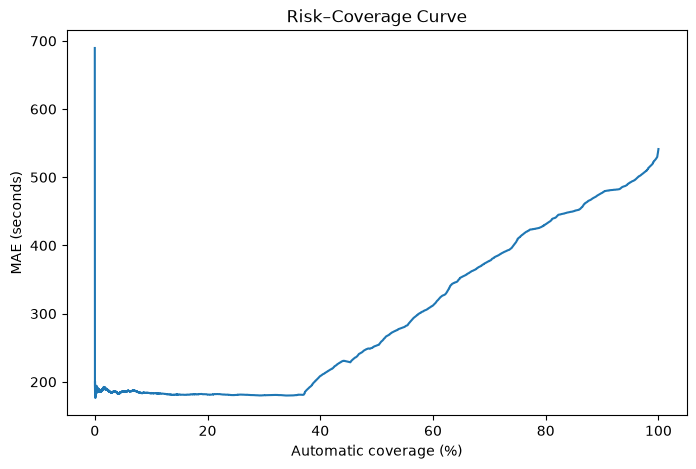

In [108]:
plt.figure(figsize=(8, 5))

plt.plot(
    risk_coverage["coverage"] * 100,
    risk_coverage["risk_mae"],
)

plt.xlabel("Automatic coverage (%)")
plt.ylabel("MAE (seconds)")
plt.title("Risk–Coverage Curve")

plt.show()

In [109]:
# Validate the repaired residualization and downstream prediction outputs.
assert len(dml_results) == len(dml_validation)
assert np.isfinite(dml_results.to_numpy()).all()
assert np.isfinite(dml_held_prob).all()
assert ((dml_held_prob >= 0) & (dml_held_prob <= 1)).all()
assert dml_treatment_model.named_steps["model"].n_iter_.max() < 5000
np.testing.assert_allclose(
    dml_results["response_residual"],
    dml_validation[TARGET].to_numpy() - dml_response_pred,
)
np.testing.assert_allclose(
    dml_results["held_residual"], dml_held_actual - dml_held_prob,
)
# Independent closed-form check of the no-intercept final regression.
held_residual = dml_results["held_residual"].to_numpy()
response_residual = dml_results["response_residual"].to_numpy()
assert held_residual @ held_residual > 0
np.testing.assert_allclose(
    dml_coefficient,
    (held_residual @ response_residual) / (held_residual @ held_residual),
)
assert len(future_cqr) == len(future) == len(future_predictions)
assert future_cqr["incident_id"].is_unique
np.testing.assert_array_equal(future_cqr["incident_id"], future["incident_id"])
np.testing.assert_allclose(future_cqr["point_pred"], future_predictions["predicted_response_seconds"])
assert np.isfinite(future_cqr[["point_pred", "lower", "upper", "uncertainty_score"]]).all().all()
assert (future_cqr["lower"] <= future_cqr["upper"]).all()
np.testing.assert_allclose(future_cqr["uncertainty_score"], future_cqr["upper"] - future_cqr["lower"])
assert len(flagged_future) == (future_cqr["uncertainty_score"] > uncertainty_threshold).sum()
np.testing.assert_allclose(flagged_percent, 100 * len(flagged_future) / len(future_cqr))
np.testing.assert_allclose(risk_coverage["risk_mae"].iloc[-1], holdout_mae)
assert risk_coverage["coverage"].iloc[-1] == 1
assert np.isfinite(risk_coverage[["coverage", "risk_mae"]]).all().all()

print("PASS: chronological split, model convergence, residuals, coefficient,")
print("      prediction alignment, finite values, intervals, flags, and risk curve.")
print(f"Adjusted observational association: {dml_coefficient:.2f} seconds")
print(f"Future predictions: {len(future_cqr):,}; flagged: {len(flagged_future):,} ({flagged_percent:.2f}%)")
print("Future accuracy and interval coverage cannot be measured without outcomes.")
display(dml_results.head())
display(future_cqr.head())

# Pressure counts must include calls excluded from outcome modeling.
probe = pd.DataFrame({
    "incident_datetime": pd.to_datetime(["2024-05-01 00:00", "2024-05-01 01:29", "2024-05-01 01:30", "2024-05-01 01:30"]),
    "initial_severity_level_code": [1, 4, 2, 3],
})
probe_features = add_model_features(probe.iloc[[2, 3]], arrivals=probe)
np.testing.assert_array_equal(probe_features["calls_last_90m"], [2, 2])
np.testing.assert_array_equal(probe_features["high_severity_calls_last_90m"], [1, 1])
for row in history_features.iloc[np.linspace(0, len(history_features)-1, 25, dtype=int)].itertuples():
    mask = (history["incident_datetime"] >= row.incident_datetime - pd.Timedelta(minutes=90)) & (history["incident_datetime"] < row.incident_datetime)
    assert row.calls_last_90m == mask.sum()
    assert row.high_severity_calls_last_90m == (mask & history["initial_severity_level_code"].between(1, 3)).sum()
assert conformal_radius(np.arange(1, 11), 0.2) == 9
assert np.isinf(conformal_radius([1], 0.1))
assert ols_model.model.rank == ols_model.model.exog.shape[1]
assert joint_design_rank < joint_design_columns
assert len(fold_results) == 21
assert np.isfinite(dev_oof[["y_true", "y_pred"]]).all().all()
assert not dev_oof.duplicated(["row_index", "model"]).any()
for fold_name, fold in folds.items():
    idx = dev_oof.loc[dev_oof["fold"] == fold_name, "row_index"]
    dates = development.loc[idx, "incident_datetime"]
    assert ((dates >= fold["val_start"]) & (dates < fold["val_end"])).all()
assert development["incident_datetime"].max() < holdout["incident_datetime"].min()
assert holdout["incident_datetime"].max() < future_features["incident_datetime"].min()
assert np.isfinite(cqr_holdout_predictions[["lower", "upper", "point_pred"]]).all().all()
assert (cqr_holdout_predictions["lower"] <= cqr_holdout_predictions["upper"]).all()
assert np.isfinite(holdout_hmm["hmm_pred"]).all()
assert np.isfinite(kalman_holdout["kalman_pred"]).all()
print("PASS: raw-history pressure counts, timestamp boundaries, conformal rank,")
print("      OLS identifiability, backtest alignment, temporal splits, and state forecasts.")
print(f"M1 holdout MAE: {holdout_mae:.2f} seconds")
print(f"M1 + HMM MAE: {hmm_holdout_mae:.2f} seconds")
print(f"M1 + Kalman MAE: {kalman_mae:.2f} seconds")
print(f"Holdout interval coverage: {holdout_coverage:.2%} (nominal 90%)")
display(comparison_results)


PASS: chronological split, model convergence, residuals, coefficient,
      prediction alignment, finite values, intervals, flags, and risk curve.
Adjusted observational association: 1480.29 seconds
Future predictions: 30,197; flagged: 4,087 (13.53%)
Future accuracy and interval coverage cannot be measured without outcomes.


,response_residual,held_residual
0,214.750186,-0.033552
1,-880.770782,-0.246204
2,-701.792514,0.764619
3,-25.902499,-0.226211
4,-232.776785,-0.060395


,incident_id,point_pred,lower,upper,uncertainty_score,flag
0,80690035,843.483528,0.0,1098.969535,1098.969535,0
1,80690037,418.633472,0.0,834.406862,834.406862,0
2,80690038,780.475908,0.0,1085.663773,1085.663773,0
3,80690040,442.080300,0.0,877.350730,877.350730,0
4,80690041,426.056274,0.0,849.628573,849.628573,0


/var/folders/3n/1bth3ytx1pb_279891wc62n00000gr/T/ipykernel_76451/912722606.py:52: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  mask = (history["incident_datetime"] >= row.incident_datetime - pd.Timedelta(minutes=90)) & (history["incident_datetime"] < row.incident_datetime)


PASS: raw-history pressure counts, timestamp boundaries, conformal rank,
      OLS identifiability, backtest alignment, temporal splits, and state forecasts.
M1 holdout MAE: 541.42 seconds
M1 + HMM MAE: 537.80 seconds
M1 + Kalman MAE: 541.63 seconds
Holdout interval coverage: 84.45% (nominal 90%)


,model,signed_error,mae,p90
0,M1_Linear,-5.36,587.58,1068.93
1,M_state_Linear,17.34,590.45,1068.41
